In [176]:
### Check Remote-other 44 to inward arrow (Smallholders)

In [4]:
Evap = (xr.open_mfdataset('/home/chandra/data/Temp_data_evap/Upscaled/Ensemble_FLUXCOM_BESS_PML/Evaporation.Ensemble_(equal_wgt).FLUXCOM(RS).BESS.PML_0.25res_daily_*.nc').Evaporation.groupby('time.year').sum('time')).mean(axis = 0).sel(lat = slice(-50,50)).values

In [8]:
Prec = xr.open_mfdataset('/home/chandra/data/CHIRPS_Precipitation/Chirps/lonlatbox0360/MAP/chirps-v2.0.*.days_p25.nc').precip.mean(axis = 0).values

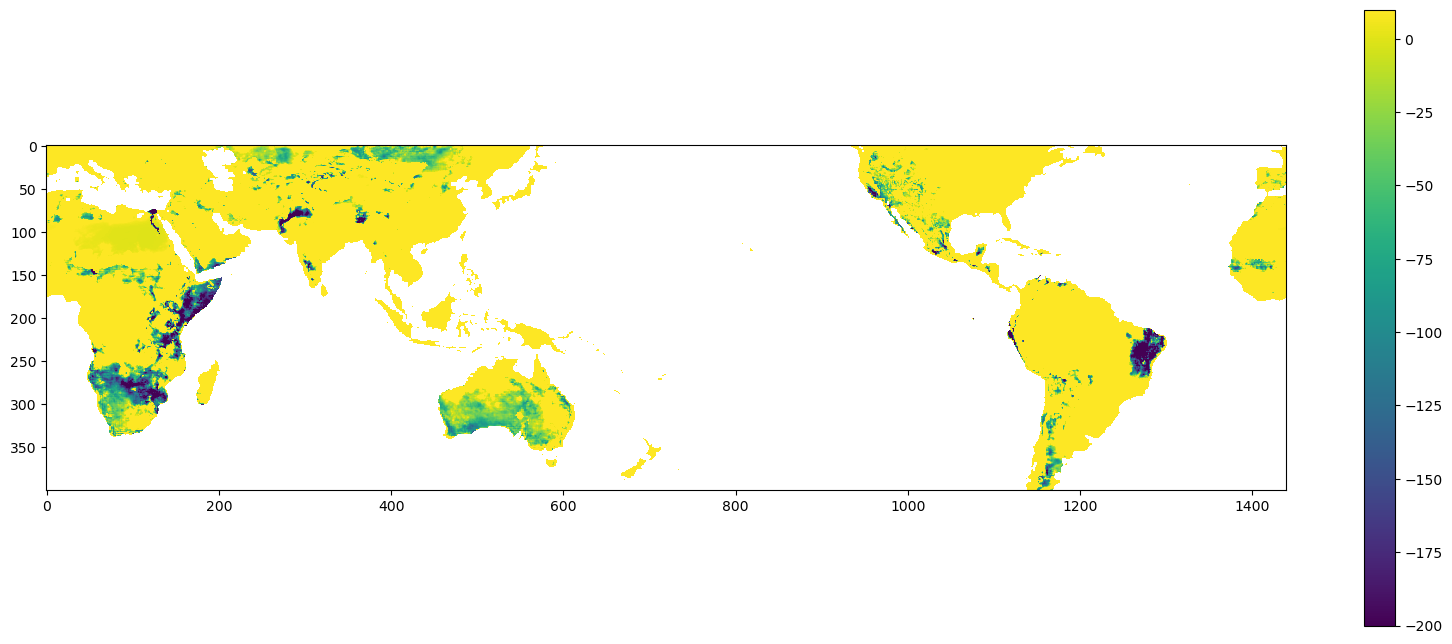

In [16]:
fig = plt.figure(figsize=(20, 8))

plt.imshow((Prec - Evap)[::-1], vmax = 10, vmin = -200)
plt.colorbar()

In [1]:
Landuse_map = 'Mapbiomas'

In [2]:
import xarray as xr
import numpy as np
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy
import pandas as pd

/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


In [3]:
LU_Mapbiomas_forest = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Mapbiomas_LU_forest.tif')[0,::-1]
LU_Mapbiomas_forest['x'] = LU_Mapbiomas_forest.x.values%360
LU_Mapbiomas_forest = LU_Mapbiomas_forest.sortby('x')
#LU_Mapbiomas = LU_Mapbiomas.sel(y = slice(-45, 15), x = slice(270, 330))
LU_Mapbiomas_forest = LU_Mapbiomas_forest.sel(y = slice(-39.25, 10.25), x = slice(280, 330))
LU_Mapbiomas_forest = LU_Mapbiomas_forest.where(LU_Mapbiomas_forest != 0)

/tmp/user/1011/ipykernel_184331/754290407.py:1: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  LU_Mapbiomas_forest = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Mapbiomas_LU_forest.tif')[0,::-1]


In [4]:
Stakeholder = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc')[0,::-1,:-1]
Stakeholder['x'] = Stakeholder.x.values%360

/tmp/user/1011/ipykernel_184331/3478874843.py:1: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Stakeholder = xr.open_rasterio('/home/chandra/data/Paper4/Output/Actor_dominance_'+Landuse_map+'.nc')[0,::-1,:-1]


In [5]:
grid_area = xr.open_dataset('/home/chandra/data/Paper4/gridarea_0.5.nc').cell_area.sel(lat = slice(-39.25, 10.25), lon = slice(280, 330))[:,1:]
grid_area = grid_area.where(Stakeholder.values>0)

/home/chandra/.local/lib/python3.10/site-packages/xarray/backends/plugins.py:64: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [6]:
P_era5 = xr.open_mfdataset('/home/chandra/data/Stable_unstable_paper/Era5_precipitation/ERA5_daily/era5_precipitation_daily_daysum_*_p25.nc').tp[:,::-1].sel(time = slice('2008','2017'), latitude = slice(-45, 15), longitude = slice(270, 330))
P_era5 = P_era5[:,:-1,:-1]*(1000)
P_era5 = P_era5.resample(time = '1M').sum('time')
P_era5 = (P_era5.groupby('time.month').mean('time'))
P_era5 = P_era5.coarsen(latitude = 2, longitude = 2).mean()

In [7]:
P_era5 = P_era5.values

Text(0.5, 1.0, 'Forest')

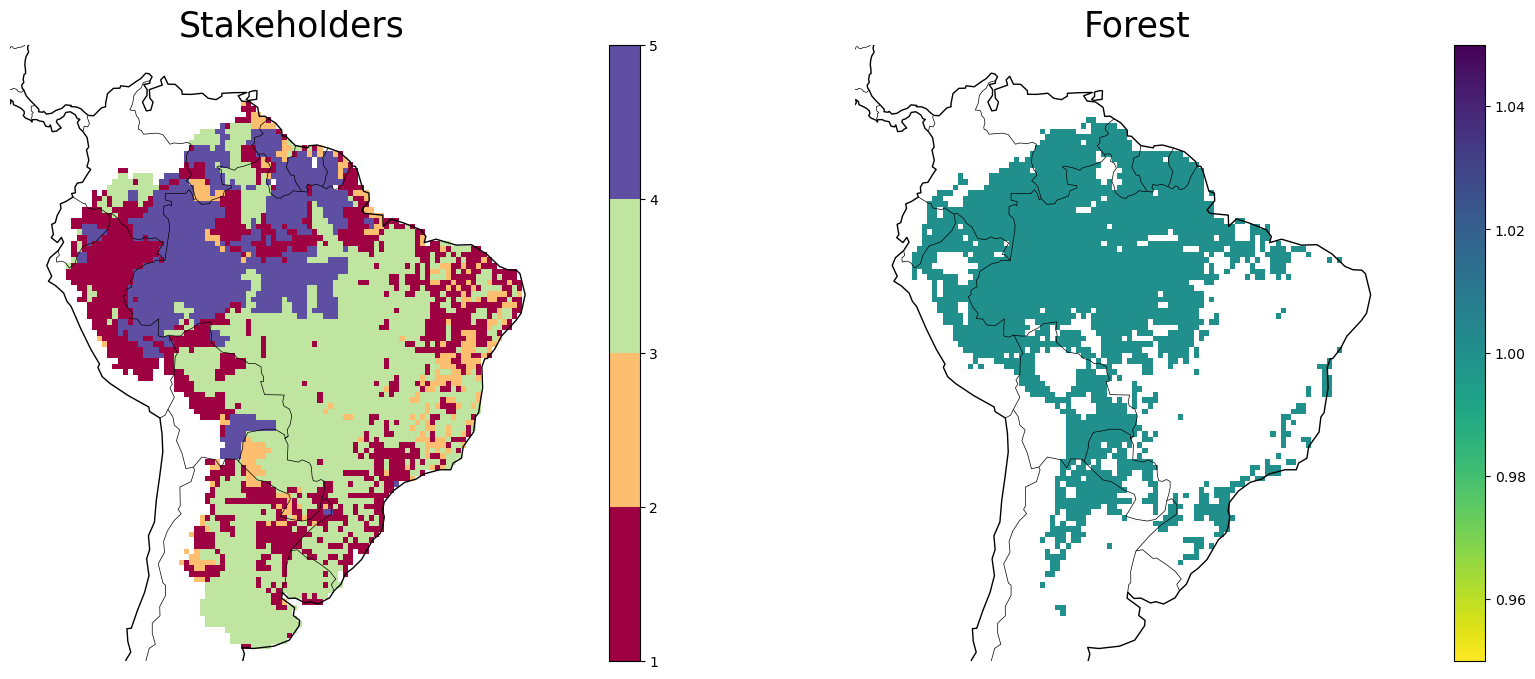

In [8]:
fig = plt.figure(figsize=(20, 8))
ax = [plt.subplot(121,projection=ccrs.PlateCarree(), aspect='auto'), plt.subplot(122,projection=ccrs.PlateCarree(), aspect='auto')]
Stakeholder.plot(ax = ax[0], cmap = 'Spectral', levels = [1,2,3,4,5])
LU_Mapbiomas_forest.plot(ax = ax[1], vmin = 1, vmax = 1, cmap = 'viridis_r')

for i in range(2):
    ax[i].coastlines(lw = 1)
    ax[i].add_feature(cartopy.feature.BORDERS, linestyle='-', alpha=1, lw = 0.5)
    ax[i].set_xlim(-85,-30)
    ax[i].set_ylim(-40, 15)
    ax[i].axis('off')
    
ax[0].set_title('Stakeholders', fontsize = '25')
ax[1].set_title('Forest', fontsize = '25')

In [9]:
def Water_footprint_stakeholder(stakeholder):
    Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+Landuse_map+'.nc').Evap_footprint[:,::-1].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,:-1]
    Water_footprint = xr.where(Water_footprint > P_era5, P_era5, Water_footprint)
    Water_footprint = Water_footprint.sum(dim = 'month')
    Water_footprint = Water_footprint.sel(lat = slice(-39.25,10.25), lon = slice(280,330))
    Water_footprint = Water_footprint.where(Stakeholder.values>0)
    Water_footprint = ((Water_footprint/10**6)*(grid_area.values/10**6))
    return Water_footprint

def Water_footprint_stakeholder_forest(stakeholder):
    Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+Landuse_map+'_Forest_only.nc').Evap_footprint[:,::-1].sel(lat = slice(-45, 15), lon = slice(270, 330))[:,:,:-1]
    Water_footprint = xr.where(Water_footprint > P_era5, P_era5, Water_footprint)
    Water_footprint = Water_footprint.sum(dim = 'month')
    Water_footprint = Water_footprint.sel(lat = slice(-39.25,10.25), lon = slice(280,330))
    Water_footprint = Water_footprint.where(Stakeholder.values>0)
    Water_footprint = ((Water_footprint/10**6)*(grid_area.values/10**6))
    return Water_footprint

def Grid(Class):
    Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]
    Grid_conv['x'] = Grid_conv.x.values%360
    Grid_conv = Grid_conv.sortby('y')
    #LU_Mapbiomas = LU_Mapbiomas.sel(y = slice(-45, 15), x = slice(270, 330))
    Grid_conv = Grid_conv.sel(y = slice(-39.25, 10.25), x = slice(280, 330))
    return Grid_conv

def stakeholder_LU_footprint_dataframe(stakeholder, simulation = 'All'):
    if simulation == 'Forest_only':
        Water_footprint = Water_footprint_stakeholder_forest(stakeholder)
        sim_add = '<br>forest'
    else:
        Water_footprint = Water_footprint_stakeholder(stakeholder)
        sim_add = ''
    print('All_Water_footprint_'+stakeholder,np.nansum(Water_footprint.values))
    if stakeholder == 'Smallholders':
        stakeholder_name = 'Smallholders'+sim_add
    if stakeholder == 'Mediumholders':
        stakeholder_name = 'Medium<br>landholders'+sim_add
    if stakeholder == 'Largeholders':
        stakeholder_name = 'Large<br>landholders'+sim_add
    #Water_f_total = np.nansum(Water_footprint.values)
    for i in range(1,5):
        WF_SM = Water_footprint.where(Stakeholder.values == i)
        if i == 1:
            Sink = 'Smallholders'
        if i == 2:
            Sink = 'Medium<br>landholders'
        if i == 3:
            Sink = 'Large<br>landholders'
        if i == 4:
            Sink = ' Remote'
        if i == 5:
            continue
        #print('Water_footprint_'+stakeholder+'_to_'+Sink, np.nansum(WF_SM.values))
        Total = np.nansum(WF_SM.values)
        a = []
        a.append(np.nansum((Grid('Forest').values*WF_SM).values))
        a.append(np.nansum((Grid('NonForest').values*WF_SM).values))
        a.append(np.nansum((Grid('Crop').values*WF_SM).values))
        a.append(np.nansum((Grid('Pasture').values*WF_SM).values))
        a.append(Total-np.sum(a))
        #print(a)
        if i == 1:
            df = pd.DataFrame({'Source': [stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name], 
                               'Stakeholder_sink': [Sink,Sink,Sink,Sink,Sink],
                               'Landuse': ['Forest', 'Non forest', 'Crop', 'Pasture', 'Others'],
                               'Footprint': np.array(a).flatten()})
        else:
            df_add = pd.DataFrame({'Source': [stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name], 
                               'Stakeholder_sink': [Sink,Sink,Sink,Sink,Sink],
                               'Landuse': ['Forest', 'Non forest', 'Crop', 'Pasture', 'Others'],
                               'Footprint': np.array(a).flatten()})
            df = pd.concat([df,df_add], ignore_index=True)
    df_other = pd.DataFrame({'Source': [stakeholder_name], 
                               'Stakeholder_sink': ['Other'],
                               'Landuse': ['Others'],
                               'Footprint': np.nansum(Water_footprint.values)-df['Footprint'].sum()})
    df = pd.concat([df,df_other], ignore_index=True)
    return df

$\text{km}^{3} \text{yr}^{-1}$

All_Water_footprint_Smallholders 2999.333303480364


/tmp/user/1011/ipykernel_184331/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


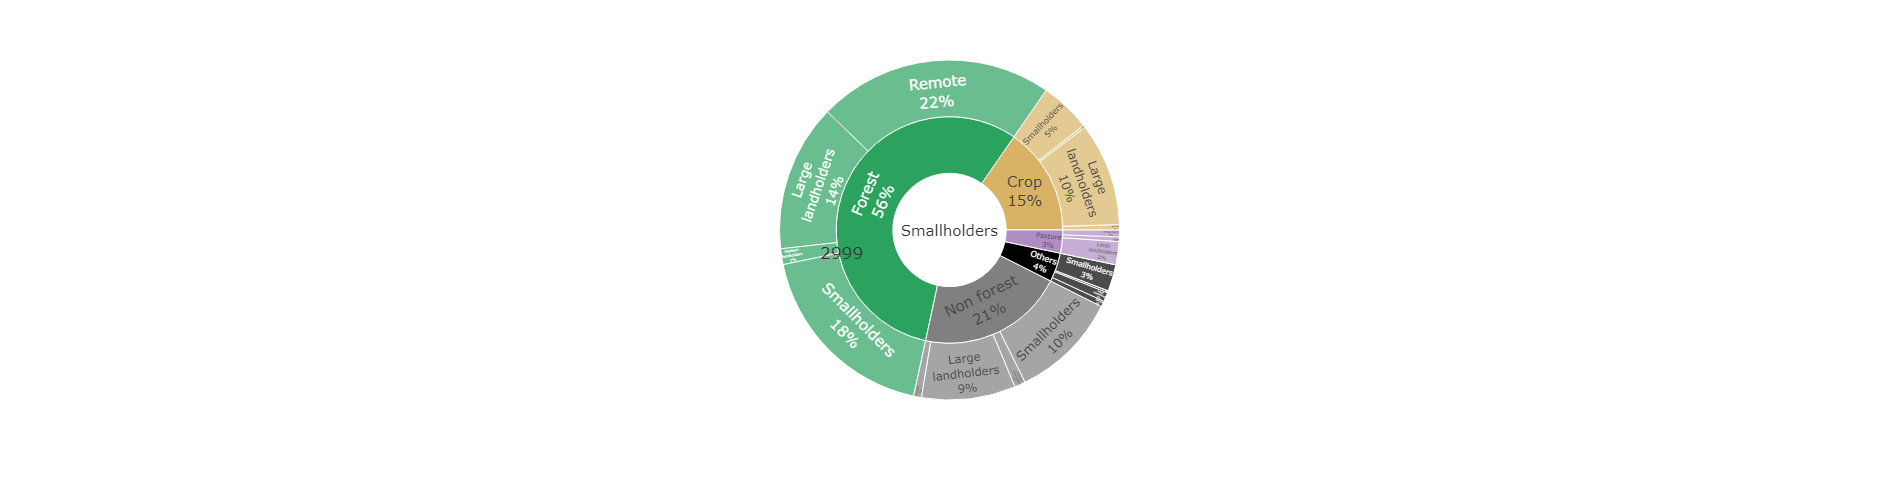

All_Water_footprint_Mediumholders 602.4870331270097


/tmp/user/1011/ipykernel_184331/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



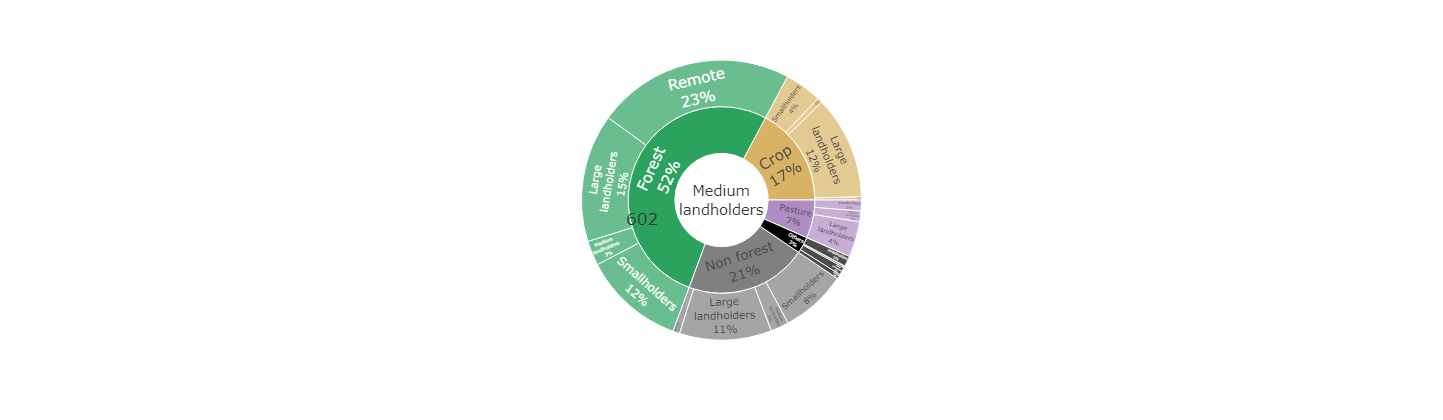

All_Water_footprint_Largeholders 4683.325098074001


/tmp/user/1011/ipykernel_184331/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



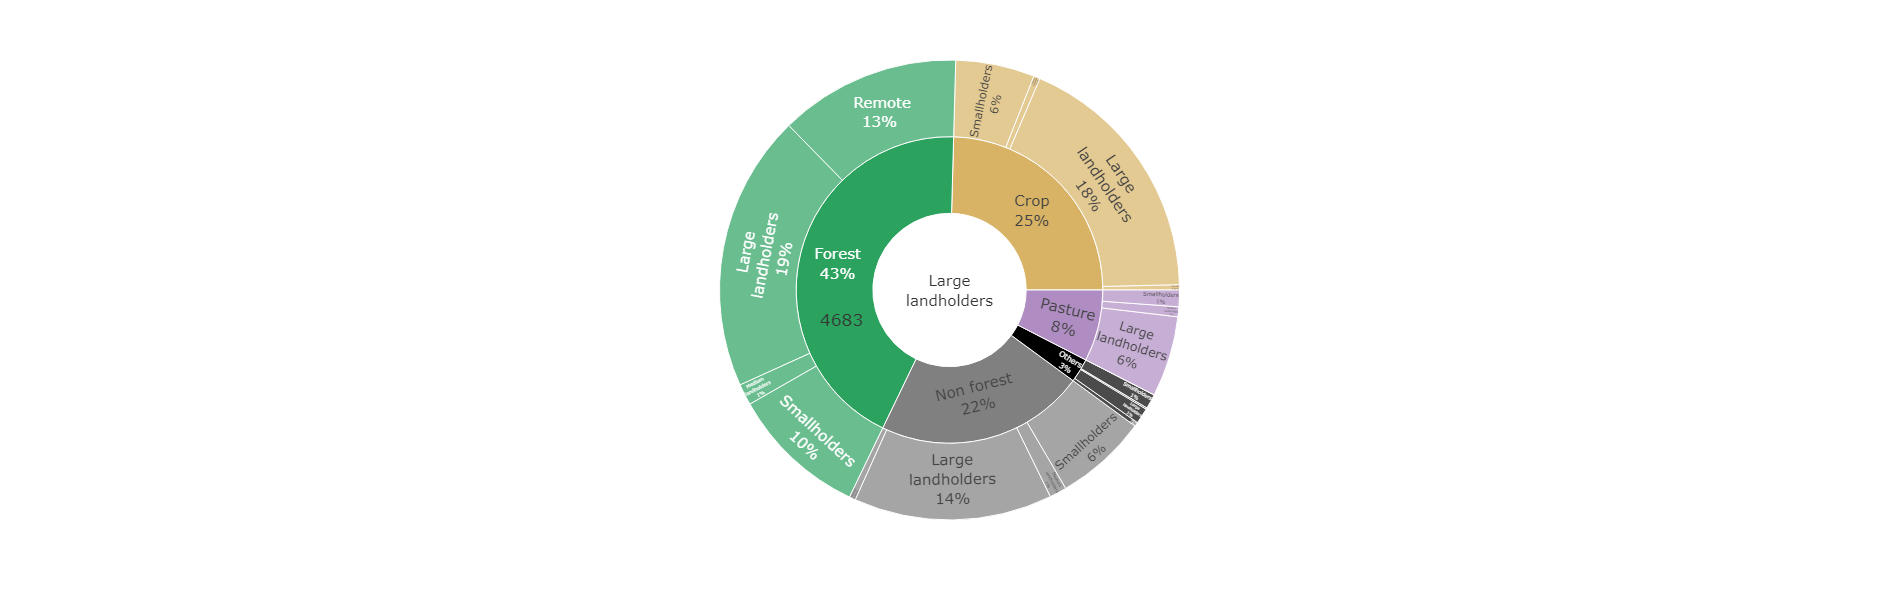

In [10]:
import plotly.express as px
import pandas as pd
import plotly.graph_objs as go

matrix = []
matrix_forest = []
matrix_crop = []
matrix_pasture = []
Total_moisture = []

for stakeholder in ['Smallholders', 'Mediumholders', 'Largeholders']:
    data = stakeholder_LU_footprint_dataframe(stakeholder)
    if stakeholder == 'Smallholders':
        factor = 0.8
    if stakeholder == 'Mediumholders':
        factor = 0.7
    if stakeholder == 'Largeholders':
        factor = 1
    fig = px.sunburst(data, path=['Source', 'Landuse','Stakeholder_sink'],
                      values='Footprint', width=600*factor, height=600*factor, template = 'ggplot2')
    fig.update_traces(textinfo="label+ percent root")
    fig.update_traces({"textfont": {"size": 15}})
    fig.update_traces(sort=False, selector=dict(type='sunburst'))
    Total_moisture.append(data['Footprint'].sum())
    fig.add_annotation(text=str(int(data['Footprint'].sum())), xref="paper", yref="paper", x=0.438, y=0.435, showarrow=False, font_size=17)
    fig.add_annotation(text=r'$\text{km}^{3} \text{yr}^{-1}$', xref="paper", yref="paper", x=0.565, y=0.435, showarrow=False, font_size=80)
    fig.update_traces(
    marker_colors=   ['','','','','','','','','','','','','','','','','','','','','','#d8b365','#2ca25f','grey','black','#af8dc3'] )
    #marker_colors=   ['#fee5d9','#fee5d9','#fee5d9','#fee5d9','#fee5d9','#cb181d','#cb181d','#cb181d','#cb181d','#cb181d',
    #                  '#fb6a4a','#fb6a4a','#fb6a4a','#fb6a4a','#fb6a4a','#525252','#fcae91','#fcae91','#fcae91','#fcae91','#fcae91',
    #                  '#d8b365','#2ca25f','grey','black','#af8dc3'] )
    #fig.write_image('/home/chandra/data/Paper4/Output/Moisture_flows_assessments/Moisture_flow_composition_sunburst_'+stakeholder+'_.svg')
    for Stakeholder_sink in ['Large<br>landholders', 'Medium<br>landholders', 'Smallholders']:
        matrix.append(data[data['Stakeholder_sink'] == Stakeholder_sink]['Footprint'].sum()/(data['Footprint'].sum()))
        matrix_forest.append(data[(data['Stakeholder_sink'] == Stakeholder_sink) & (data['Landuse'] == 'Forest')]['Footprint'].sum()/(data['Footprint'].sum()))
        matrix_crop.append(data[(data['Stakeholder_sink'] == Stakeholder_sink) & (data['Landuse'] == 'Crop')]['Footprint'].sum()/(data['Footprint'].sum()))
        matrix_pasture.append(data[(data['Stakeholder_sink'] == Stakeholder_sink) & (data['Landuse'] == 'Pasture')]['Footprint'].sum()/(data['Footprint'].sum()))
    fig.show()
    
matrix = np.array(matrix).reshape((3, 3))
matrix_forest = np.array(matrix_forest).reshape((3, 3))
matrix_crop = np.array(matrix_crop).reshape((3, 3))
matrix_pasture = np.array(matrix_pasture).reshape((3, 3))

In [13]:
str(np.round(int(Total_moisture[0])/1000, 1))

'4.7'

/tmp/user/1011/ipykernel_184331/2385168738.py:6: MatplotlibDeprecationWarning:


The mpl_toolkits.axes_grid module was deprecated in Matplotlib 2.1 and will be removed two minor releases later. Use mpl_toolkits.axes_grid1 and mpl_toolkits.axisartist, which provide the same functionality instead.



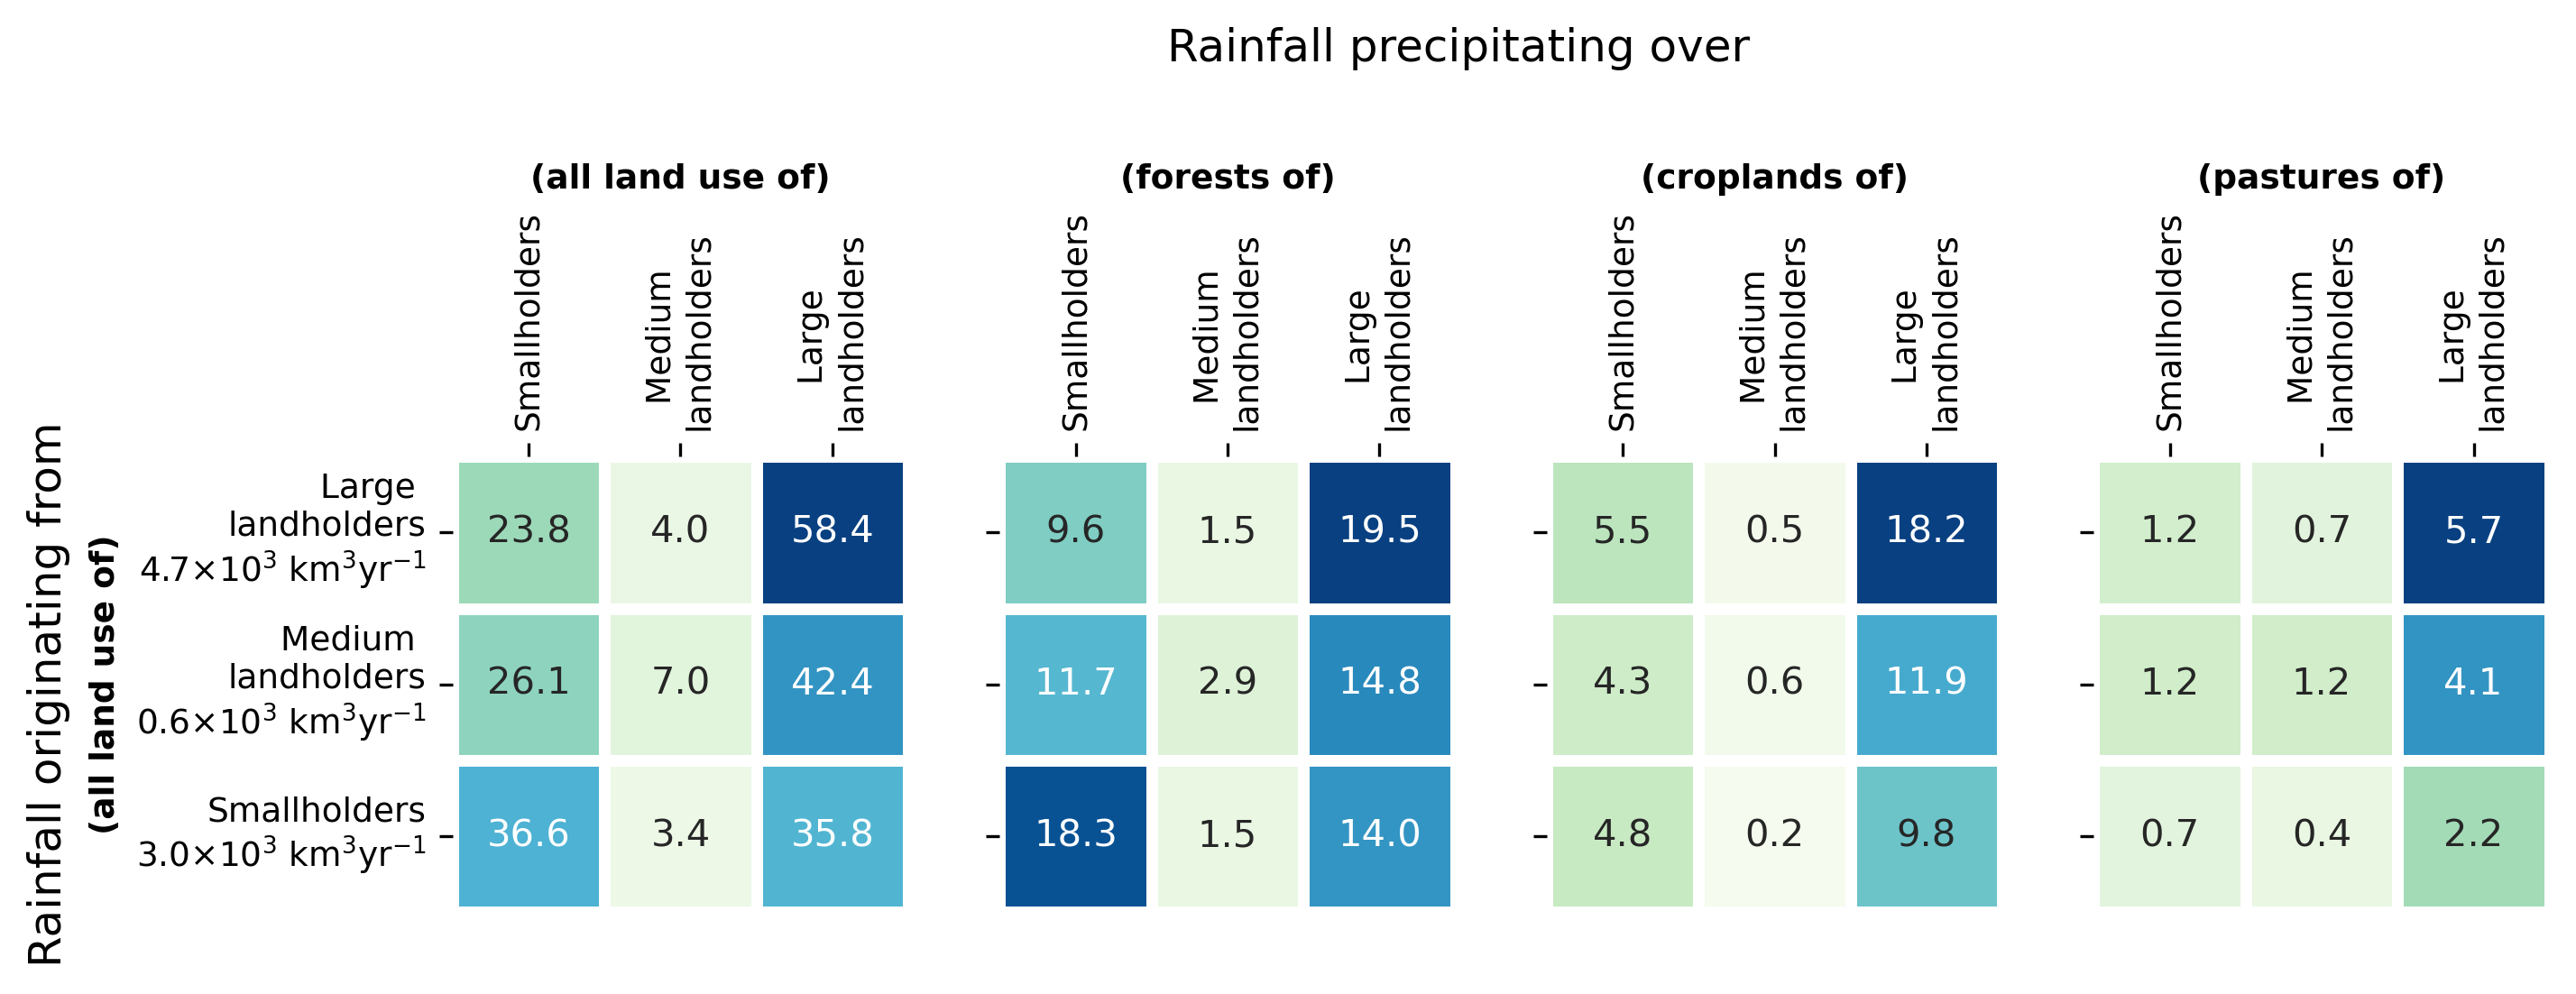

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid.inset_locator import inset_axes

Total_moisture = Total_moisture[::-1]
x_axis_labels = ['Smallholders','Medium \nlandholders','Large \nlandholders'] # labels for x-axis
y_axis_labels = ['Large \nlandholders\n'+str(np.round(int(Total_moisture[0])/1000, 1))+r'$\times10^{3}$ km$^{3}$'+'yr'+ r'$^{-1}$',
                 'Medium \nlandholders\n'+str(np.round(int(Total_moisture[1])/1000, 1))+r'$\times10^{3}$ km$^{3}$'+'yr'+ r'$^{-1}$',
                 'Smallholders\n'+str(np.round(int(Total_moisture[2])/1000, 1))+r'$\times10^{3}$ km$^{3}$'+'yr'+ r'$^{-1}$'] # labels for y-axis
fig, ax = plt.subplots(1,4, figsize=(10,2.5), sharey='col', dpi = 300)
# create seabvorn heatmap with required labels

matrix = matrix[::-1,::-1]
matrix_forest = matrix_forest[::-1,::-1]
matrix_crop = matrix_crop[::-1,::-1]
matrix_pasture = matrix_pasture[::-1,::-1]

sns.heatmap(matrix*100, square=True, linewidth=3, ax = ax[0], yticklabels=y_axis_labels, xticklabels=x_axis_labels, vmin = 0, cmap = 'GnBu',cbar = False, annot = True, fmt=".1f")
sns.heatmap(matrix_forest*100, square=True, linewidth=3, cbar_kws={"shrink": .8}, ax = ax[1], yticklabels=['','',''], xticklabels=x_axis_labels, vmin = 0, cmap = 'GnBu',cbar = False, annot = True, fmt=".1f")
sns.heatmap(matrix_crop*100, square=True, linewidth=3, cbar_kws={"shrink": .8}, ax = ax[2], yticklabels=['','',''], xticklabels=x_axis_labels, vmin = 0, cmap = 'GnBu',cbar = False, annot = True, fmt=".1f")
sns.heatmap(matrix_pasture*100, square=True, linewidth=3, cbar_kws={"shrink": .8}, ax = ax[3], yticklabels=['','',''], xticklabels=x_axis_labels, vmin = 0, cmap = 'GnBu',cbar = False, annot = True, fmt=".1f")
for i in range(4):
    #ax[i].tick_params(axis='both', which='major', labelsize=10, labelbottom = False, bottom=True, top = False, labeltop=False, rotation = 45)
    ax[i].tick_params(axis='both', which='major', labelsize=9)
    ax[i].xaxis.tick_top()

for i in range(4):
    for label in ax[i].get_xticklabels():
        label.set_rotation(90) 
    
ax[0].set_title('(all land use of)', fontweight ='bold', fontsize = 9)
ax[1].set_title('(forests of)', fontweight = 'bold', fontsize = 9)
ax[2].set_title('(croplands of)', fontweight = 'bold', fontsize = 9)
ax[3].set_title('(pastures of)', fontweight = 'bold', fontsize = 9)
ax[0].set_ylabel('(all land use of)', fontweight = 'bold', fontsize = 9)
ax[0].text(4.7,-2.6,'Rainfall precipitating over', fontsize = 12)
ax[0].text(-2.8,3.3,'Rainfall originating from', rotation = 90, fontsize = 12)

plt.show()

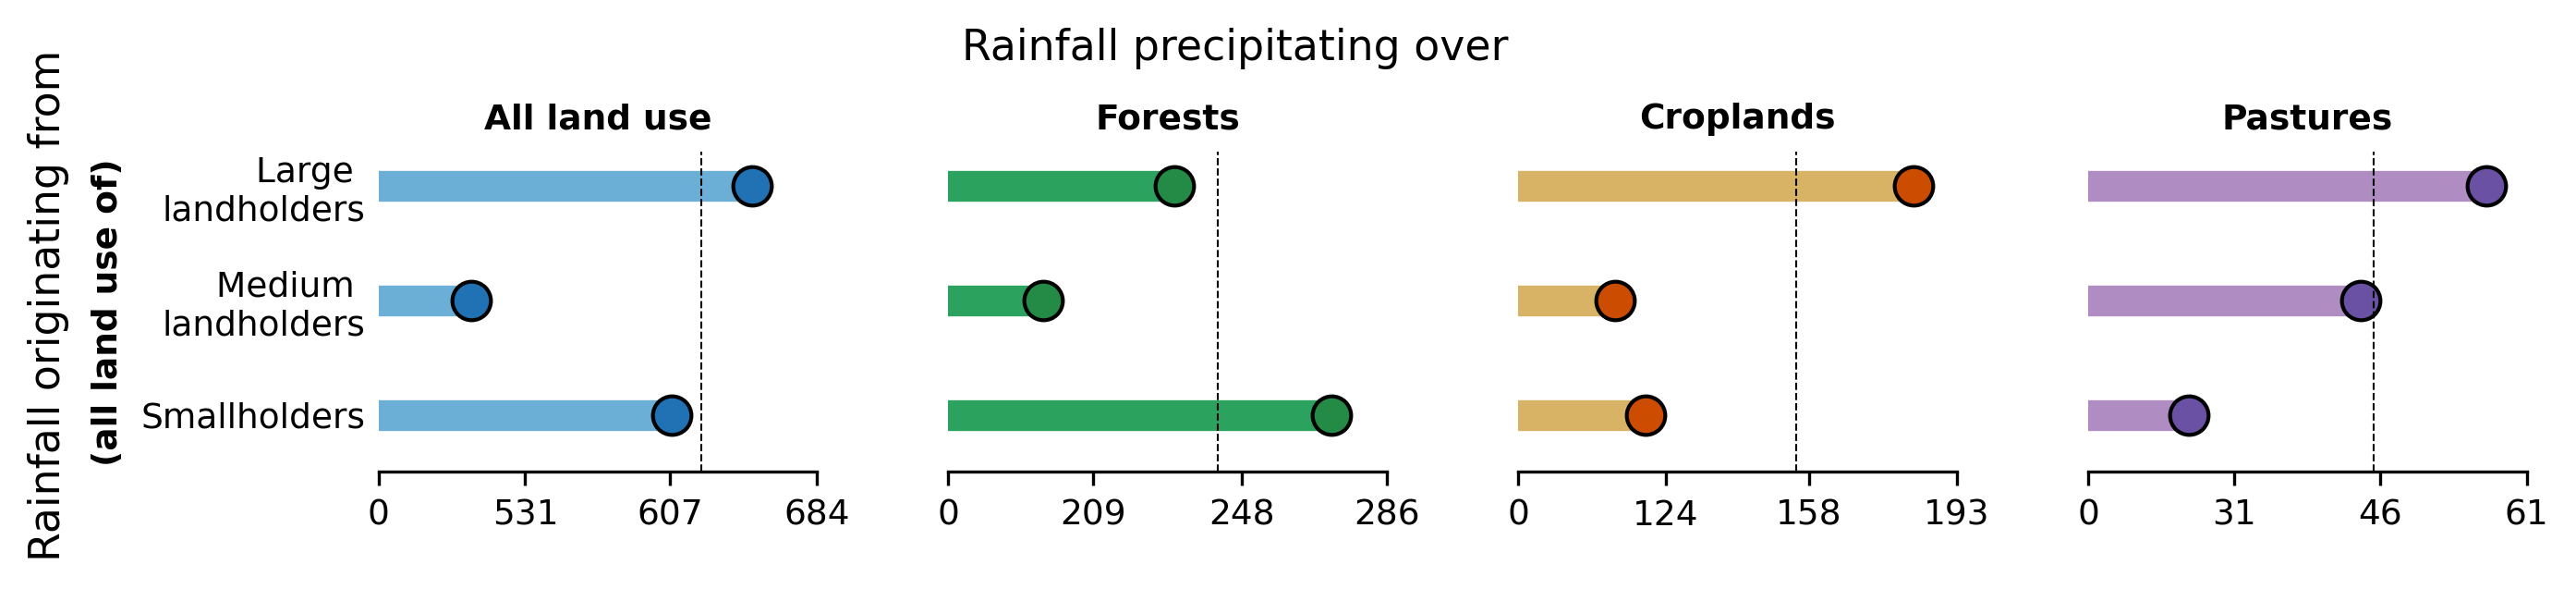

In [122]:
import numpy
from matplotlib import pyplot

fig, ax = plt.subplots(1,4, figsize=(10,1.5), sharey='col', dpi = 300)
Area_source = (np.array([6.205007,0.903514,3.739770])*(10**6))

mean = ((Total_moisture*matrix.sum(axis = 1)).sum()/(Area_source).sum())*10**6
x_arr = ((Total_moisture*matrix.sum(axis = 1))/(Area_source))[::-1]*10**6
y_arr = ['Smallholders','Medium \nlandholders','Large \nlandholders']
ax[0].hlines(y_arr, 0, x_arr, color='#6baed6', lw = 8, zorder = 0)
ax[0].scatter(x_arr, y_arr, s = 100, edgecolor = 'k', color = '#2171b5')  
ax[0].axvline(mean, 0, 1, color='k', linestyle = '--', lw = 0.5)  

x_arr.sort()
ax[0].set_xlim(np.hstack((np.round(x_arr[0]-((x_arr[2]-x_arr[0])/3)), np.round(x_arr)))[0],)

mean = ((Total_moisture*matrix_forest.sum(axis = 1)).sum()/(Area_source).sum())*10**6
x_arr = ((Total_moisture*matrix_forest.sum(axis = 1))/(Area_source))[::-1]*10**6
y_arr = ['Smallholders','Medium \nlandholders','Large \nlandholders']
ax[1].hlines(y_arr, 0, x_arr, color='#2ca25f', lw = 8, zorder = 0)
ax[1].scatter(x_arr, y_arr, s = 100, edgecolor = 'k', color = '#238b45')  
ax[1].axvline(mean, 0, 1, color='k', linestyle = '--', lw = 0.5)  
x_arr.sort()
ax[1].set_xlim(np.hstack((np.round(x_arr[0]-((x_arr[2]-x_arr[0])/3)), np.round(x_arr)))[0],)

mean = ((Total_moisture*matrix_crop.sum(axis = 1)).sum()/(Area_source).sum())*10**6
x_arr = ((Total_moisture*matrix_crop.sum(axis = 1))/(Area_source))[::-1]*10**6
y_arr = ['Smallholders','Medium \nlandholders','Large \nlandholders']
ax[2].hlines(y_arr, 0, x_arr, color='#d8b365', lw = 8, zorder = 0)
ax[2].scatter(x_arr, y_arr, s = 100, edgecolor = 'k', color = '#cc4c02')  
ax[2].axvline(mean, 0, 1, color='k', linestyle = '--', lw = 0.5)  
x_arr.sort()
ax[2].set_xlim(np.hstack((np.round(x_arr[0]-((x_arr[2]-x_arr[0])/3)), np.round(x_arr)))[0],)

mean = ((Total_moisture*matrix_pasture.sum(axis = 1)).sum()/(Area_source).sum())*10**6
x_arr = ((Total_moisture*matrix_pasture.sum(axis = 1))/(Area_source))[::-1]*10**6
y_arr = ['Smallholders','Medium \nlandholders','Large \nlandholders']
ax[3].hlines(y_arr, 0, x_arr, color='#af8dc3', lw = 8, zorder = 0)
ax[3].scatter(x_arr, y_arr, s = 100, edgecolor = 'k', color = '#6a51a3')  
ax[3].axvline(mean, 0, 1, color='k', linestyle = '--', lw = 0.5)  
x_arr.sort()
ax[3].set_xlim(np.hstack((np.round(x_arr[0]-((x_arr[2]-x_arr[0])/3)), np.round(x_arr)))[0],)

for i in range(4):
    start, end = ax[i].get_xlim()
    if start < 0:
        start = 0
    ax[i].set_xticks(np.round((np.linspace(start, end+1, 4)), 0))
    
    labels = np.round((np.linspace(start, end+1, 4)), 0).astype(int)
    labels[0] = 0
    
    ax[i].set_xticklabels(labels)



for i in range(4):
    ax[i].set_ylim(-0.5,2.3)
    ax[i].tick_params(axis='both', which='major', labelsize=9)
    ax[i].xaxis.tick_top()
    ax[i].tick_params(axis='y', which='both', length=0)
    #ax[i].set_xlabel(r'×10$^{-4}$', fontsize = 9)
    
    # Hide the right and top spines
    ax[i].spines.right.set_visible(False)
    ax[i].spines.top.set_visible(False)
    ax[i].spines.left.set_visible(False)

    # Only show ticks on the left and bottom spines
    ax[i].yaxis.set_ticks_position('left')
    ax[i].xaxis.set_ticks_position('bottom')

plt.setp(ax[1].get_yticklabels(), visible=False)
plt.setp(ax[2].get_yticklabels(), visible=False)
plt.setp(ax[3].get_yticklabels(), visible=False)

ax[0].set_title('All land use', fontweight ='bold', fontsize = 9)
ax[1].set_title('Forests', fontweight = 'bold', fontsize = 9)
ax[2].set_title('Croplands', fontweight = 'bold', fontsize = 9)
ax[3].set_title('Pastures', fontweight = 'bold', fontsize = 9)
ax[0].set_ylabel('(all land use of)', fontweight = 'bold', fontsize = 9)
ax[0].text(760,3.1,'Rainfall precipitating over', fontsize = 11)
ax[0].text(270,-1.2,'Rainfall originating from', rotation = 90, fontsize = 11)

#ax[0].text(7,-1.8,'Volume of water per year', fontsize = 11)
#ax[0].text(7.8,-2.3,'Area', fontsize = 11)
#ax[0].text(9.65,-1.8,r'km$^{3}$'+'yr'+ r'$^{-1}$', fontsize = 11)
#ax[0].text(9.75,-2.3,r'km$^2$', fontsize = 11)
#ax[0].text(9.15,-2.15,r'10$^{-4}$', fontsize = 11)
plt.subplots_adjust(wspace=0.3, hspace=0.1)


All_Water_footprint_Smallholders 1611.9400235586431


/tmp/user/1011/ipykernel_184331/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



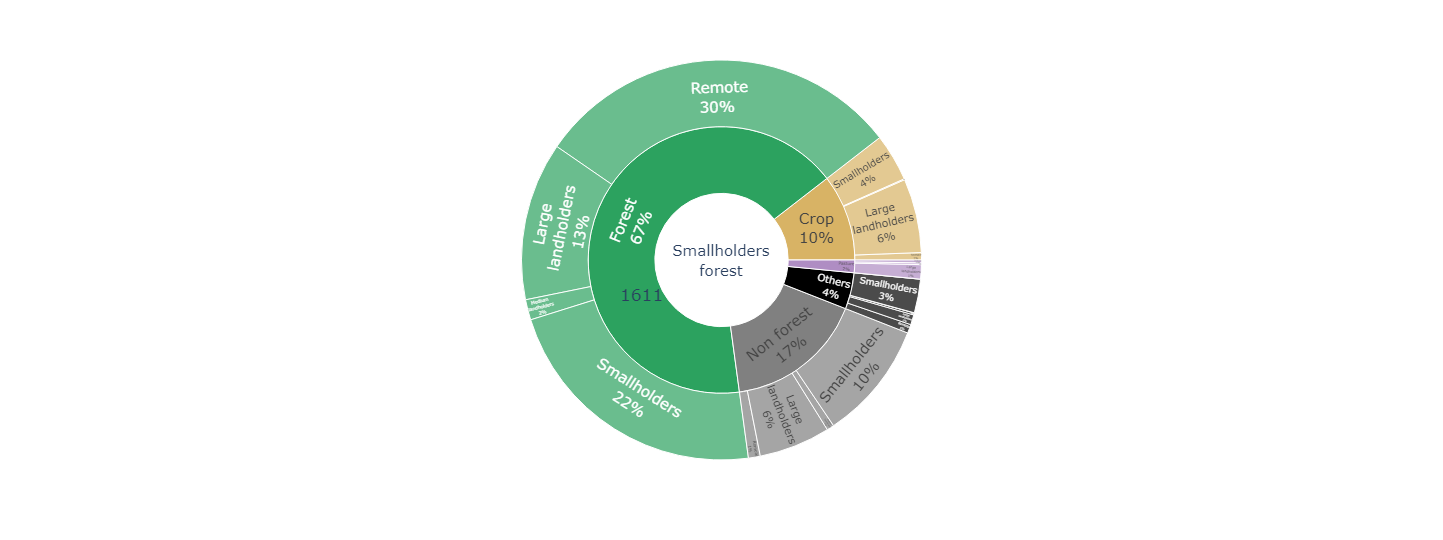

All_Water_footprint_Mediumholders 271.86511250213164


/tmp/user/1011/ipykernel_184331/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



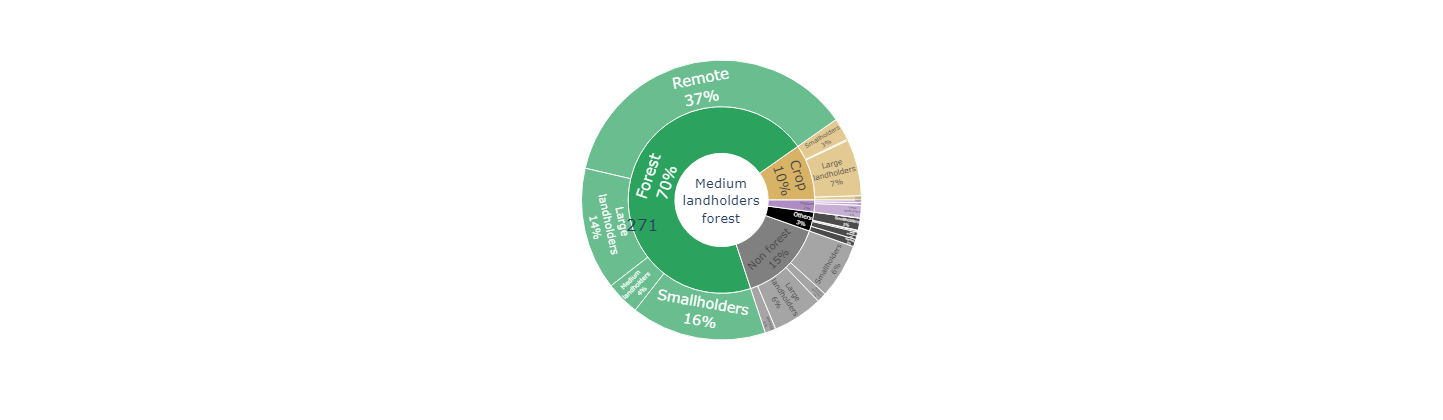

All_Water_footprint_Largeholders 2044.52611763891


/tmp/user/1011/ipykernel_184331/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



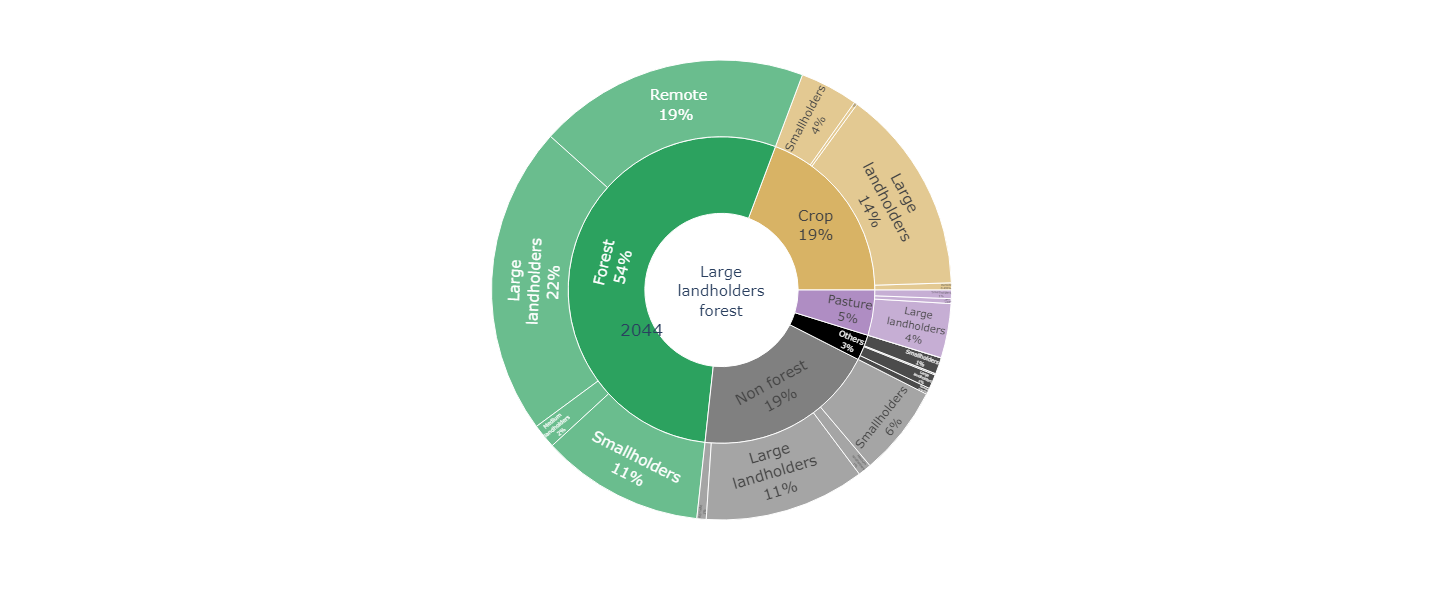

In [123]:
import plotly.express as px
import pandas as pd
import plotly.graph_objs as go

matrix = []
matrix_forest = []
matrix_crop = []
matrix_pasture = []
Total_moisture = []

for stakeholder in ['Smallholders', 'Mediumholders', 'Largeholders']:
    data = stakeholder_LU_footprint_dataframe(stakeholder, 'Forest_only')
    if stakeholder == 'Smallholders':
        factor = 0.9
    if stakeholder == 'Mediumholders':
        factor = 0.7
    if stakeholder == 'Largeholders':
        factor = 1
    fig = px.sunburst(data, path=['Source', 'Landuse','Stakeholder_sink',],
                      values='Footprint', width=600*factor, height=600*factor)
    fig.update_traces(textinfo="label+ percent root")
    fig.update_traces({"textfont": {"size": 15}})
    fig.update_traces(sort=False, selector=dict(type='sunburst'))
    Total_moisture.append(data['Footprint'].sum())
    fig.add_annotation(text=str(int(data['Footprint'].sum())), xref="paper", yref="paper", x=0.438, y=0.415, showarrow=False, font_size=17)
    fig.add_annotation(text=r'$\text{km}^{3} \text{yr}^{-1}$', xref="paper", yref="paper", x=0.565, y=0.415, showarrow=False, font_size=80)
    fig.update_traces(
    marker_colors=   ['','','','','','','','','','','','','','','','','','','','','','#d8b365','#2ca25f','grey','black','#af8dc3'] )
    #marker_colors=   ['#fb6a4a','#fb6a4a','#fb6a4a','#fb6a4a','#fb6a4a','#ffff99','#ffff99','#ffff99','#ffff99','#ffff99',
    #                  '#525252','#7fbc41','#7fbc41','#7fbc41','#7fbc41','#7fbc41','#2b8cbe','#2b8cbe','#2b8cbe','#2b8cbe','#2b8cbe',
    #                  '#d8b365','#2ca25f','grey','black','#af8dc3'] )
    #fig.write_image('/home/chandra/data/Paper4/Output/Moisture_flows_assessments/Moisture_flow_composition_sunburst_'+stakeholder+'_Forest_only.svg')
    for Stakeholder_sink in ['Large<br>landholders', 'Medium<br>landholders', 'Smallholders']:
        matrix.append(data[data['Stakeholder_sink'] == Stakeholder_sink]['Footprint'].sum()/(data['Footprint'].sum()))
        matrix_forest.append(data[(data['Stakeholder_sink'] == Stakeholder_sink) & (data['Landuse'] == 'Forest')]['Footprint'].sum()/(data['Footprint'].sum()))
        matrix_crop.append(data[(data['Stakeholder_sink'] == Stakeholder_sink) & (data['Landuse'] == 'Crop')]['Footprint'].sum()/(data['Footprint'].sum()))
        matrix_pasture.append(data[(data['Stakeholder_sink'] == Stakeholder_sink) & (data['Landuse'] == 'Pasture')]['Footprint'].sum()/(data['Footprint'].sum()))
    fig.show()
    
matrix = np.array(matrix).reshape((3, 3))
matrix_forest = np.array(matrix_forest).reshape((3, 3))
matrix_crop = np.array(matrix_crop).reshape((3, 3))
matrix_pasture = np.array(matrix_pasture).reshape((3, 3))

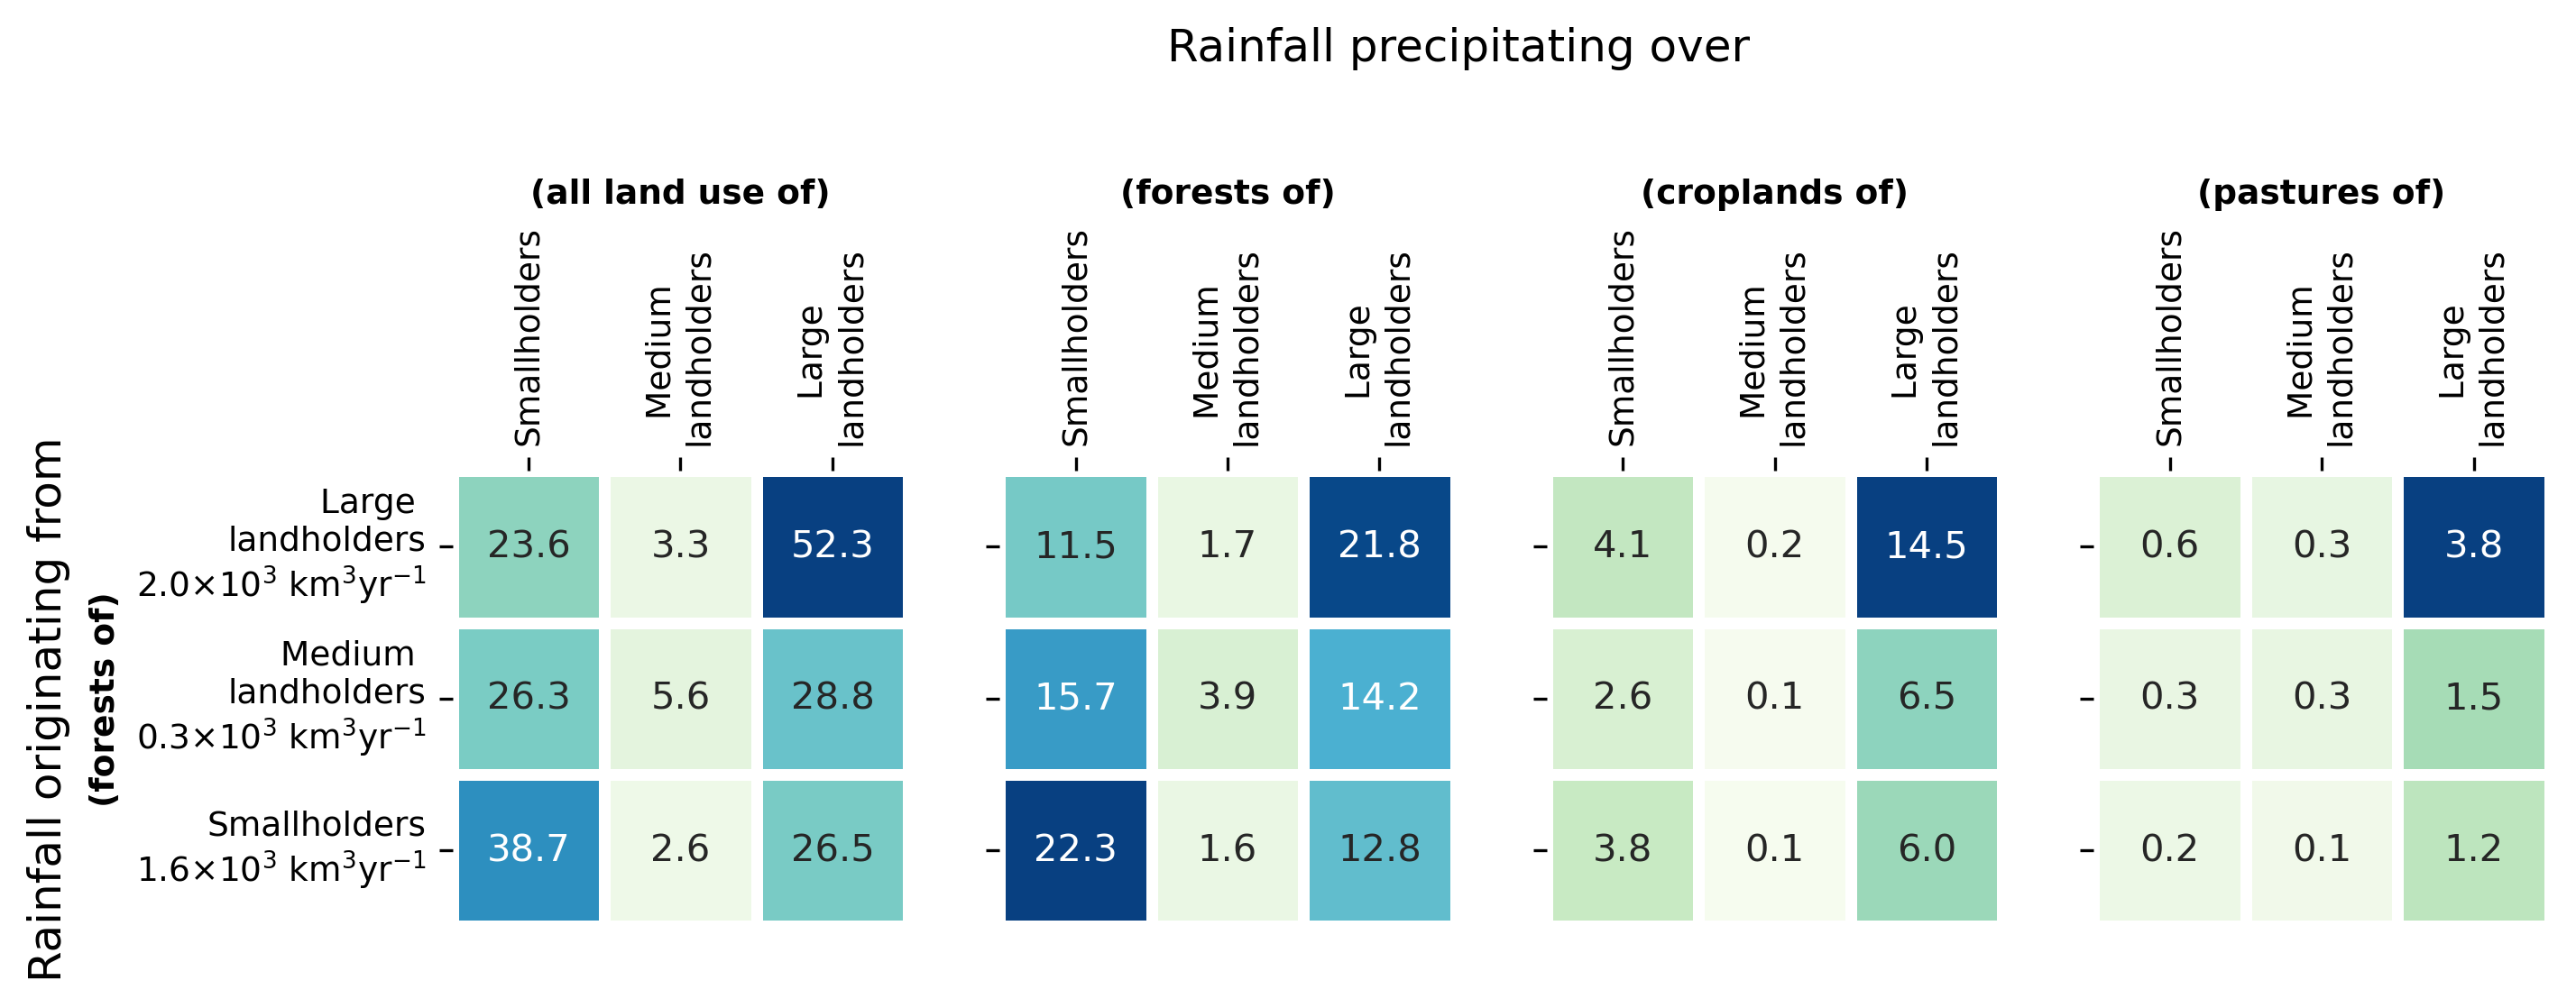

In [124]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid.inset_locator import inset_axes

Total_moisture = Total_moisture[::-1]
x_axis_labels = ['Smallholders','Medium \nlandholders','Large \nlandholders'] # labels for x-axis
y_axis_labels = ['Large \nlandholders\n'+str(np.round(int(Total_moisture[0])/1000, 1))+r'$\times10^{3}$ km$^{3}$'+'yr'+ r'$^{-1}$',
                 'Medium \nlandholders\n'+str(np.round(int(Total_moisture[1])/1000, 1))+r'$\times10^{3}$ km$^{3}$'+'yr'+ r'$^{-1}$',
                 'Smallholders\n'+str(np.round(int(Total_moisture[2])/1000, 1))+r'$\times10^{3}$ km$^{3}$'+'yr'+ r'$^{-1}$'] # labels for y-axis
fig, ax = plt.subplots(1,4, figsize=(10,2.5), sharey='col', dpi = 300)
# create seabvorn heatmap with required labels

matrix = matrix[::-1,::-1]
matrix_forest = matrix_forest[::-1,::-1]
matrix_crop = matrix_crop[::-1,::-1]
matrix_pasture = matrix_pasture[::-1,::-1]

sns.heatmap(matrix*100, square=True, linewidth=3, ax = ax[0], yticklabels=y_axis_labels, xticklabels=x_axis_labels, vmin = 0, cmap = 'GnBu',cbar = False, annot = True, fmt=".1f")
sns.heatmap(matrix_forest*100, square=True, linewidth=3, cbar_kws={"shrink": .8}, ax = ax[1], yticklabels=['','',''], xticklabels=x_axis_labels, vmin = 0, cmap = 'GnBu',cbar = False, annot = True, fmt=".1f")
sns.heatmap(matrix_crop*100, square=True, linewidth=3, cbar_kws={"shrink": .8}, ax = ax[2], yticklabels=['','',''], xticklabels=x_axis_labels, vmin = 0, cmap = 'GnBu',cbar = False, annot = True, fmt=".1f")
sns.heatmap(matrix_pasture*100, square=True, linewidth=3, cbar_kws={"shrink": .8}, ax = ax[3], yticklabels=['','',''], xticklabels=x_axis_labels, vmin = 0, cmap = 'GnBu',cbar = False, annot = True, fmt=".1f")
for i in range(4):
    #ax[i].tick_params(axis='both', which='major', labelsize=10, labelbottom = False, bottom=True, top = False, labeltop=False, rotation = 45)
    ax[i].tick_params(axis='both', which='major', labelsize=9)
    ax[i].xaxis.tick_top()

for i in range(4):
    for label in ax[i].get_xticklabels():
        label.set_rotation(90) 
    
ax[0].set_title('(all land use of)', fontweight ='bold', fontsize = 9)
ax[1].set_title('(forests of)', fontweight = 'bold', fontsize = 9)
ax[2].set_title('(croplands of)', fontweight = 'bold', fontsize = 9)
ax[3].set_title('(pastures of)', fontweight = 'bold', fontsize = 9)
ax[0].set_ylabel('(forests of)', fontweight = 'bold', fontsize = 9)
ax[0].text(4.7,-2.7,'Rainfall precipitating over', fontsize = 12)
ax[0].text(-2.8,3.3,'Rainfall originating from', rotation = 90, fontsize = 12)

plt.show()

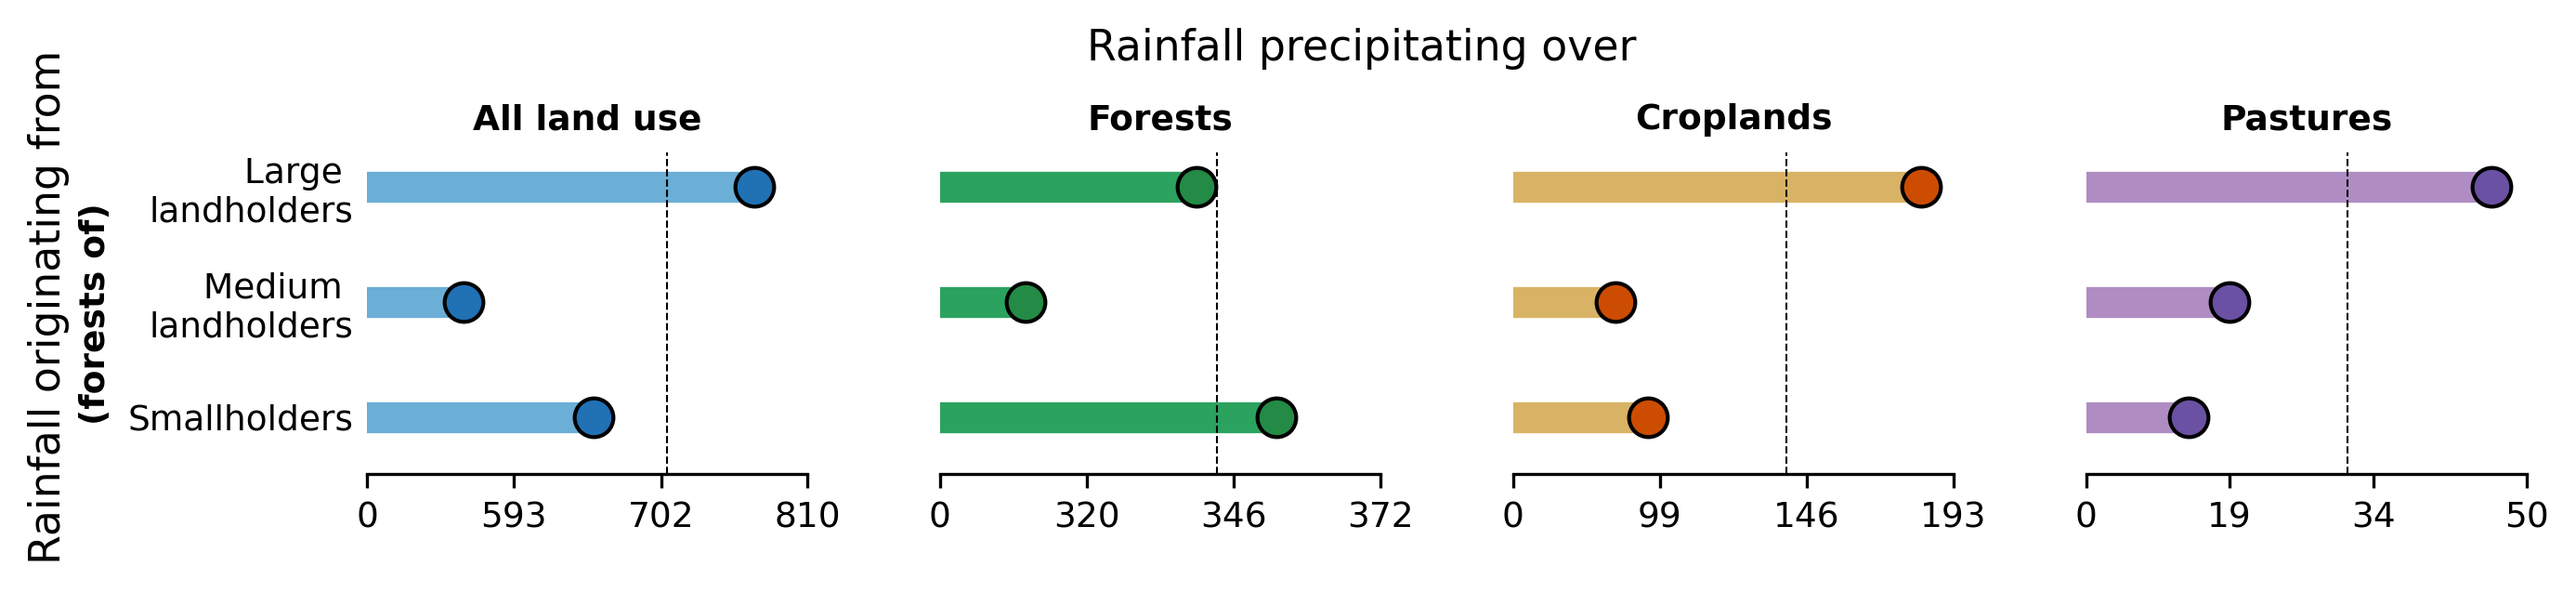

In [131]:
import numpy
from matplotlib import pyplot

fig, ax = plt.subplots(1,4, figsize=(10,1.5), sharey='col', dpi = 300)

Area_source = (np.array([2.104104,0.296609,1.676165])*(10**6))

mean = ((Total_moisture*matrix.sum(axis = 1)).sum()/(Area_source).sum())*10**6
x_arr = ((Total_moisture*matrix.sum(axis = 1))/(Area_source))[::-1]*10**6
y_arr = ['Smallholders','Medium \nlandholders','Large \nlandholders']
ax[0].hlines(y_arr, 0, x_arr, color='#6baed6', lw = 8, zorder = 0)
ax[0].scatter(x_arr, y_arr, s = 100, edgecolor = 'k', color = '#2171b5')  
ax[0].axvline(mean, 0, 1, color='k', linestyle = '--', lw = 0.5)  

x_arr.sort()
ax[0].set_xlim(np.hstack((np.round(x_arr[0]-((x_arr[2]-x_arr[0])/3)), np.round(x_arr)))[0],)

mean = ((Total_moisture*matrix_forest.sum(axis = 1)).sum()/(Area_source).sum())*10**6
x_arr = ((Total_moisture*matrix_forest.sum(axis = 1))/(Area_source))[::-1]*10**6
y_arr = ['Smallholders','Medium \nlandholders','Large \nlandholders']
ax[1].hlines(y_arr, 0, x_arr, color='#2ca25f', lw = 8, zorder = 0)
ax[1].scatter(x_arr, y_arr, s = 100, edgecolor = 'k', color = '#238b45')  
ax[1].axvline(mean, 0, 1, color='k', linestyle = '--', lw = 0.5)  
x_arr.sort()
ax[1].set_xlim(np.hstack((np.round(x_arr[0]-((x_arr[2]-x_arr[0])/3)), np.round(x_arr)))[0],)

mean = ((Total_moisture*matrix_crop.sum(axis = 1)).sum()/(Area_source).sum())*10**6
x_arr = ((Total_moisture*matrix_crop.sum(axis = 1))/(Area_source))[::-1]*10**6
y_arr = ['Smallholders','Medium \nlandholders','Large \nlandholders']
ax[2].hlines(y_arr, 0, x_arr, color='#d8b365', lw = 8, zorder = 0)
ax[2].scatter(x_arr, y_arr, s = 100, edgecolor = 'k', color = '#cc4c02')  
ax[2].axvline(mean, 0, 1, color='k', linestyle = '--', lw = 0.5)  
x_arr.sort()
ax[2].set_xlim(np.hstack((np.round(x_arr[0]-((x_arr[2]-x_arr[0])/3)), np.round(x_arr)))[0],)

mean = ((Total_moisture*matrix_pasture.sum(axis = 1)).sum()/(Area_source).sum())*10**6
x_arr = ((Total_moisture*matrix_pasture.sum(axis = 1))/(Area_source))[::-1]*10**6
y_arr = ['Smallholders','Medium \nlandholders','Large \nlandholders']
ax[3].hlines(y_arr, 0, x_arr, color='#af8dc3', lw = 8, zorder = 0)
ax[3].scatter(x_arr, y_arr, s = 100, edgecolor = 'k', color = '#6a51a3')  
ax[3].axvline(mean, 0, 1, color='k', linestyle = '--', lw = 0.5)  
x_arr.sort()
ax[3].set_xlim(np.hstack((np.round(x_arr[0]-((x_arr[2]-x_arr[0])/3)), np.round(x_arr)))[0],)

for i in range(4):
    start, end = ax[i].get_xlim()
    if start < 0:
        start = 0
    ax[i].set_xticks(np.round((np.linspace(start, end+1, 4)), 0))
    
    labels = np.round((np.linspace(start, end+1, 4)), 0).astype(int)
    labels[0] = 0
    
    ax[i].set_xticklabels(labels)


for i in range(4):
    ax[i].set_ylim(-0.5,2.3)
    ax[i].tick_params(axis='both', which='major', labelsize=9)
    ax[i].xaxis.tick_top()
    ax[i].tick_params(axis='y', which='both', length=0)
    #ax[i].set_xlabel(r'×10$^{-4}$', fontsize = 9)
    
    # Hide the right and top spines
    ax[i].spines.right.set_visible(False)
    ax[i].spines.top.set_visible(False)
    ax[i].spines.left.set_visible(False)

    # Only show ticks on the left and bottom spines
    ax[i].yaxis.set_ticks_position('left')
    ax[i].xaxis.set_ticks_position('bottom')

plt.setp(ax[1].get_yticklabels(), visible=False)
plt.setp(ax[2].get_yticklabels(), visible=False)
plt.setp(ax[3].get_yticklabels(), visible=False)

ax[0].set_title('All land use', fontweight ='bold', fontsize = 9)
ax[1].set_title('Forests', fontweight = 'bold', fontsize = 9)
ax[2].set_title('Croplands', fontweight = 'bold', fontsize = 9)
ax[3].set_title('Pastures', fontweight = 'bold', fontsize = 9)
ax[0].set_ylabel('(forests of)', fontweight = 'bold', fontsize = 9)
ax[1].text(320,3.1,'Rainfall precipitating over', fontsize = 11)
ax[0].text(235,-1.2,'Rainfall originating from', rotation = 90, fontsize = 11)

#ax[1].text(2.7,-1.8,'Rainfall originating from (specific) landholder per year', fontsize = 11)
#ax[1].text(3.0,-2.3,'Forest area of the (specific) landholder', fontsize = 11)
#x[0].text(5.3,-1.8,r'km$^{3}$'+'yr'+ r'$^{-1}$', fontsize = 11)
#x[0].text(5.4,-2.3,r'km$^2$', fontsize = 11)
#x[0].text(4.95,-2.15,r'10$^{-4}$', fontsize = 11)
plt.subplots_adjust(wspace=0.3, hspace=0.1)


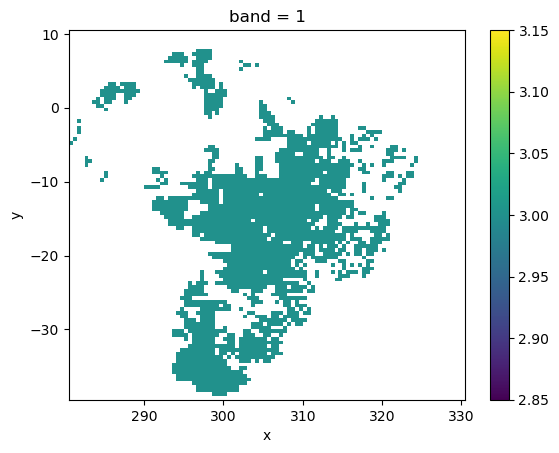

In [49]:
Stakeholder.where(Stakeholder== 3).plot()

In [369]:
def Water_footprint_stakeholder_local(stakeholder,grid):
    Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+str(grid)+'x'+str(grid)+'_.nc').Evap_footprint[::-1,:].sel(lat = slice(-39.25,10.25), lon = slice(280,330))[:,:-1]
    Water_footprint = Water_footprint.where(Stakeholder.values>0)
    Water_footprint = ((Water_footprint/10**6)*(grid_area.values/10**6))
    return Water_footprint

def Water_footprint_stakeholder_local_forest(stakeholder,grid):
    Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+str(grid)+'x'+str(grid)+'_forest.nc').Evap_footprint[::-1,:].sel(lat = slice(-39.25,10.25), lon = slice(280,330))[:,:-1]
    Water_footprint = Water_footprint.where(Stakeholder.values>0)
    Water_footprint = ((Water_footprint/10**6)*(grid_area.values/10**6))
    return Water_footprint

def stakeholder_LU_footprint_dataframe_local(stakeholder, grid, simulation = 'All'):
    if simulation == 'Forest_only':
        Water_footprint = Water_footprint_stakeholder_local_forest(stakeholder, grid)
        sim_add = '<br>forest'
    else:
        Water_footprint = Water_footprint_stakeholder_local(stakeholder, grid)
        sim_add = ''
    print('All_Water_footprint_'+stakeholder,np.nansum(Water_footprint.values))
    if stakeholder == 'Smallholders':
        stakeholder_name = 'Smallholders'+sim_add
    if stakeholder == 'Mediumholders':
        stakeholder_name = 'Medium<br>landholders'+sim_add
    if stakeholder == 'Largeholders':
        stakeholder_name = 'Large<br>landholders'+sim_add
    #Water_f_total = np.nansum(Water_footprint.values)
    for i in range(1,5):
        WF_SM = Water_footprint.where(Stakeholder.values == i)
        if i == 1:
            Sink = 'Smallholders'
        if i == 2:
            Sink = 'Medium<br>landholders'
        if i == 3:
            Sink = 'Large<br>landholders'
        if i == 4:
            Sink = ' Remote'
        if i == 5:
            continue
        #print('Water_footprint_'+stakeholder+'_to_'+Sink, np.nansum(WF_SM.values))
        Total = np.nansum(WF_SM.values)
        a = []
        a.append(np.nansum((Grid('Forest').values*WF_SM).values))
        a.append(np.nansum((Grid('NonForest').values*WF_SM).values))
        a.append(np.nansum((Grid('Crop').values*WF_SM).values))
        a.append(np.nansum((Grid('Pasture').values*WF_SM).values))
        a.append(Total-np.sum(a))
        #print(a)
        if i == 1:
            df = pd.DataFrame({'Source': [stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name], 
                               'Stakeholder_sink': [Sink,Sink,Sink,Sink,Sink],
                               'Landuse': ['Forest', 'Non forest', 'Crop', 'Pasture', 'Others'],
                               'Footprint': np.array(a).flatten()})
        else:
            df_add = pd.DataFrame({'Source': [stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name], 
                               'Stakeholder_sink': [Sink,Sink,Sink,Sink,Sink],
                               'Landuse': ['Forest', 'Non forest', 'Crop', 'Pasture', 'Others'],
                               'Footprint': np.array(a).flatten()})
            df = pd.concat([df,df_add], ignore_index=True)
    df_other = pd.DataFrame({'Source': [stakeholder_name], 
                               'Stakeholder_sink': ['Other'],
                               'Landuse': ['Others'],
                               'Footprint': np.nansum(Water_footprint.values)-df['Footprint'].sum()})
    df = pd.concat([df,df_other], ignore_index=True)
    return df

In [16]:
def recycling_influence_log(xs, ys, color, ax=None, **kwargs):
    global fit_y, MAX_X
    MAX_X = 2000
    ax.scatter(xs, ys, color='b', s = 150, edgecolor = 'k', facecolor = color)
    # do fit
    tmp_A = []
    tmp_B = []
    for i in range(len(xs)):
        tmp_A.append([np.log(xs[i]), 1])
        tmp_B.append(ys[i])
    B = np.matrix(tmp_B).T
    A = np.matrix(tmp_A)
    fit = (A.T * A).I * A.T * B
    errors = B - A * fit
    residual = np.linalg.norm(errors)

    print("solution:")
    print("%f log(x) + %f = y" % (fit[0], fit[1]))
    print("errors:")
    print(errors)
    print("residual:")
    print(residual)

    # plot fit
    fit_x = range(1, MAX_X)
    fit_y = [float(fit[0]) * np.log(x) + float(fit[1]) for x in fit_x]
    ax.plot(fit_x, fit_y, color=color, lw = 1, zorder = -2)
    ax.plot(fit_x, fit_y, linestyle="dashed", dashes=(5, 10), color='k', lw = 0.5, zorder = -1)

    ax.set_xlabel('x')
    ax.set_ylabel('y')
    #ax.set_xlim(0,1100)
    #ax.set_ylim(0,100)

All_Water_footprint_Smallholders 548.2745476759737


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


All_Water_footprint_Smallholders 2999.333303480364


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


All_Water_footprint_Smallholders 1245.0314603520687
All_Water_footprint_Smallholders 2999.333303480364
All_Water_footprint_Smallholders 1656.2657376692077


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


... (16 outputs left out)

All_Water_footprint_Largeholders 4683.325098074001
All_Water_footprint_Largeholders 3126.4021059087477


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


All_Water_footprint_Largeholders 4683.325098074001
solution:
36.124492 log(x) + -184.702718 = y
errors:
[[ 1.00074352]
 [-1.34954657]
 [-1.57079896]
 [ 1.91960201]]
residual:
2.995837911218245


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


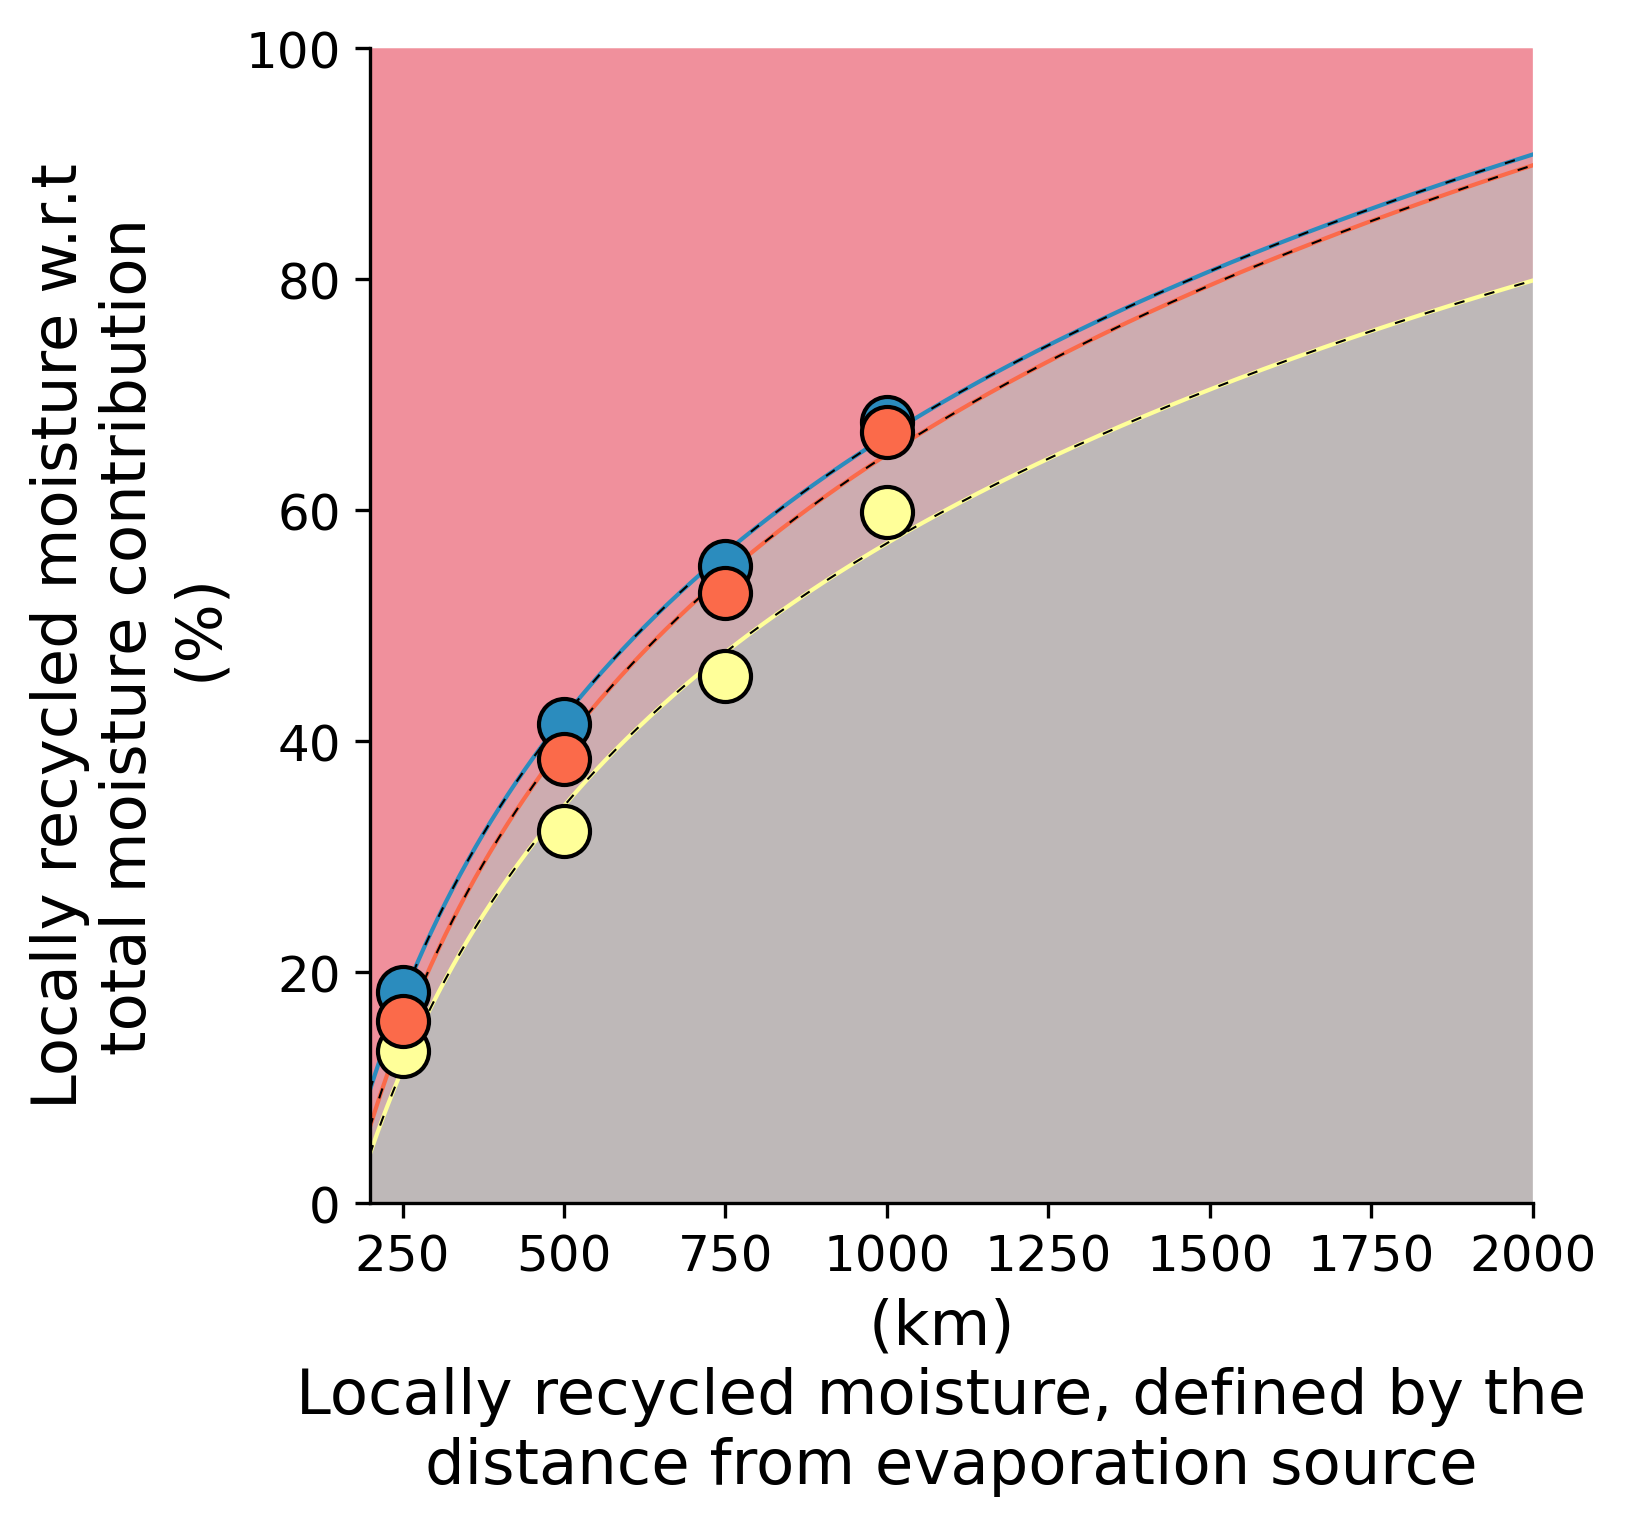

In [391]:
##### For all landuse

fig, ax = plt.subplots(1,1, figsize=(5,5), dpi = 300)
color_f = ['#ada6a6','#ed7281'] #['#5ab4ac', '#ed7281']
for stakeholders, color in zip(['Smallholders','Mediumholders', 'Largeholders'], ['#2B8CBE','#FFFF99','#FB6A4A']):
    loc_recycling_dist = []
    for grid in [9,19,27,37]:
        sr, total = stakeholder_LU_footprint_dataframe_local(stakeholders, grid, simulation = 'All')['Footprint'].sum(), stakeholder_LU_footprint_dataframe(stakeholders)['Footprint'].sum()
        sr = sr/total*100
        loc_recycling_dist.append(sr)
    recycling_influence_log([250,500,750,1000], loc_recycling_dist, color = color, ax = ax)
    ax.fill_between(np.linspace(0,MAX_X,np.array(fit_y).shape[0]), np.array(fit_y), step="pre", 
                    alpha=0.4, color = color_f[0], edgecolor = None, zorder = -10)
    ax.fill_between(np.linspace(0,MAX_X,np.array(fit_y).shape[0]), np.array(fit_y), 100, 
                    step="pre", alpha=0.4, color = color_f[1], edgecolor = None, zorder = -10)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.tick_params(axis='x',          # changes apply to the x-axis
                which='both',      # both major and minor ticks are affected
                bottom=True,      # ticks along the bottom edge are off
                top=False,         # ticks along the top edge are off
                labelbottom=True)
ax.set_ylim(0,100)
#ax.set_xlim(200,1100)
ax.set_xticks(np.arange(250, 2001, 250))
ax.set_xlabel('(km) \nLocally recycled moisture, defined by the \ndistance from evaporation source', fontsize = 15)
ax.set_ylabel('Locally recycled moisture w.r.t \ntotal moisture contribution \n(%)', fontsize = 15)
ax.set_xlim(200,MAX_X)

plt.show()


In [6]:
print(np.median(np.array([548.274,1245,1656,2029])/2999))
print(np.median(np.array([79,194,275,360])/602))
print(np.median(np.array([737,1800,2476,3126])/4683))

0.48366122040680226
0.38953488372093026
0.45654494981849236


All_Water_footprint_Smallholders 291.9287175240809
All_Water_footprint_Smallholders 1611.9400235586431


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]
/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


All_Water_footprint_Smallholders 683.1626853950627
All_Water_footprint_Smallholders 1611.9400235586431


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


All_Water_footprint_Smallholders 913.2666565520879
All_Water_footprint_Smallholders 1611.9400235586431


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


... (15 outputs left out)

/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


All_Water_footprint_Largeholders 1317.9714848584229
All_Water_footprint_Largeholders 2044.52611763891


/tmp/ipykernel_44350/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


solution:
35.193993 log(x) + -180.952777 = y
errors:
[[ 1.24969707]
 [-1.75084988]
 [-1.80355815]
 [ 2.30471096]]
residual:
3.6320424935904168


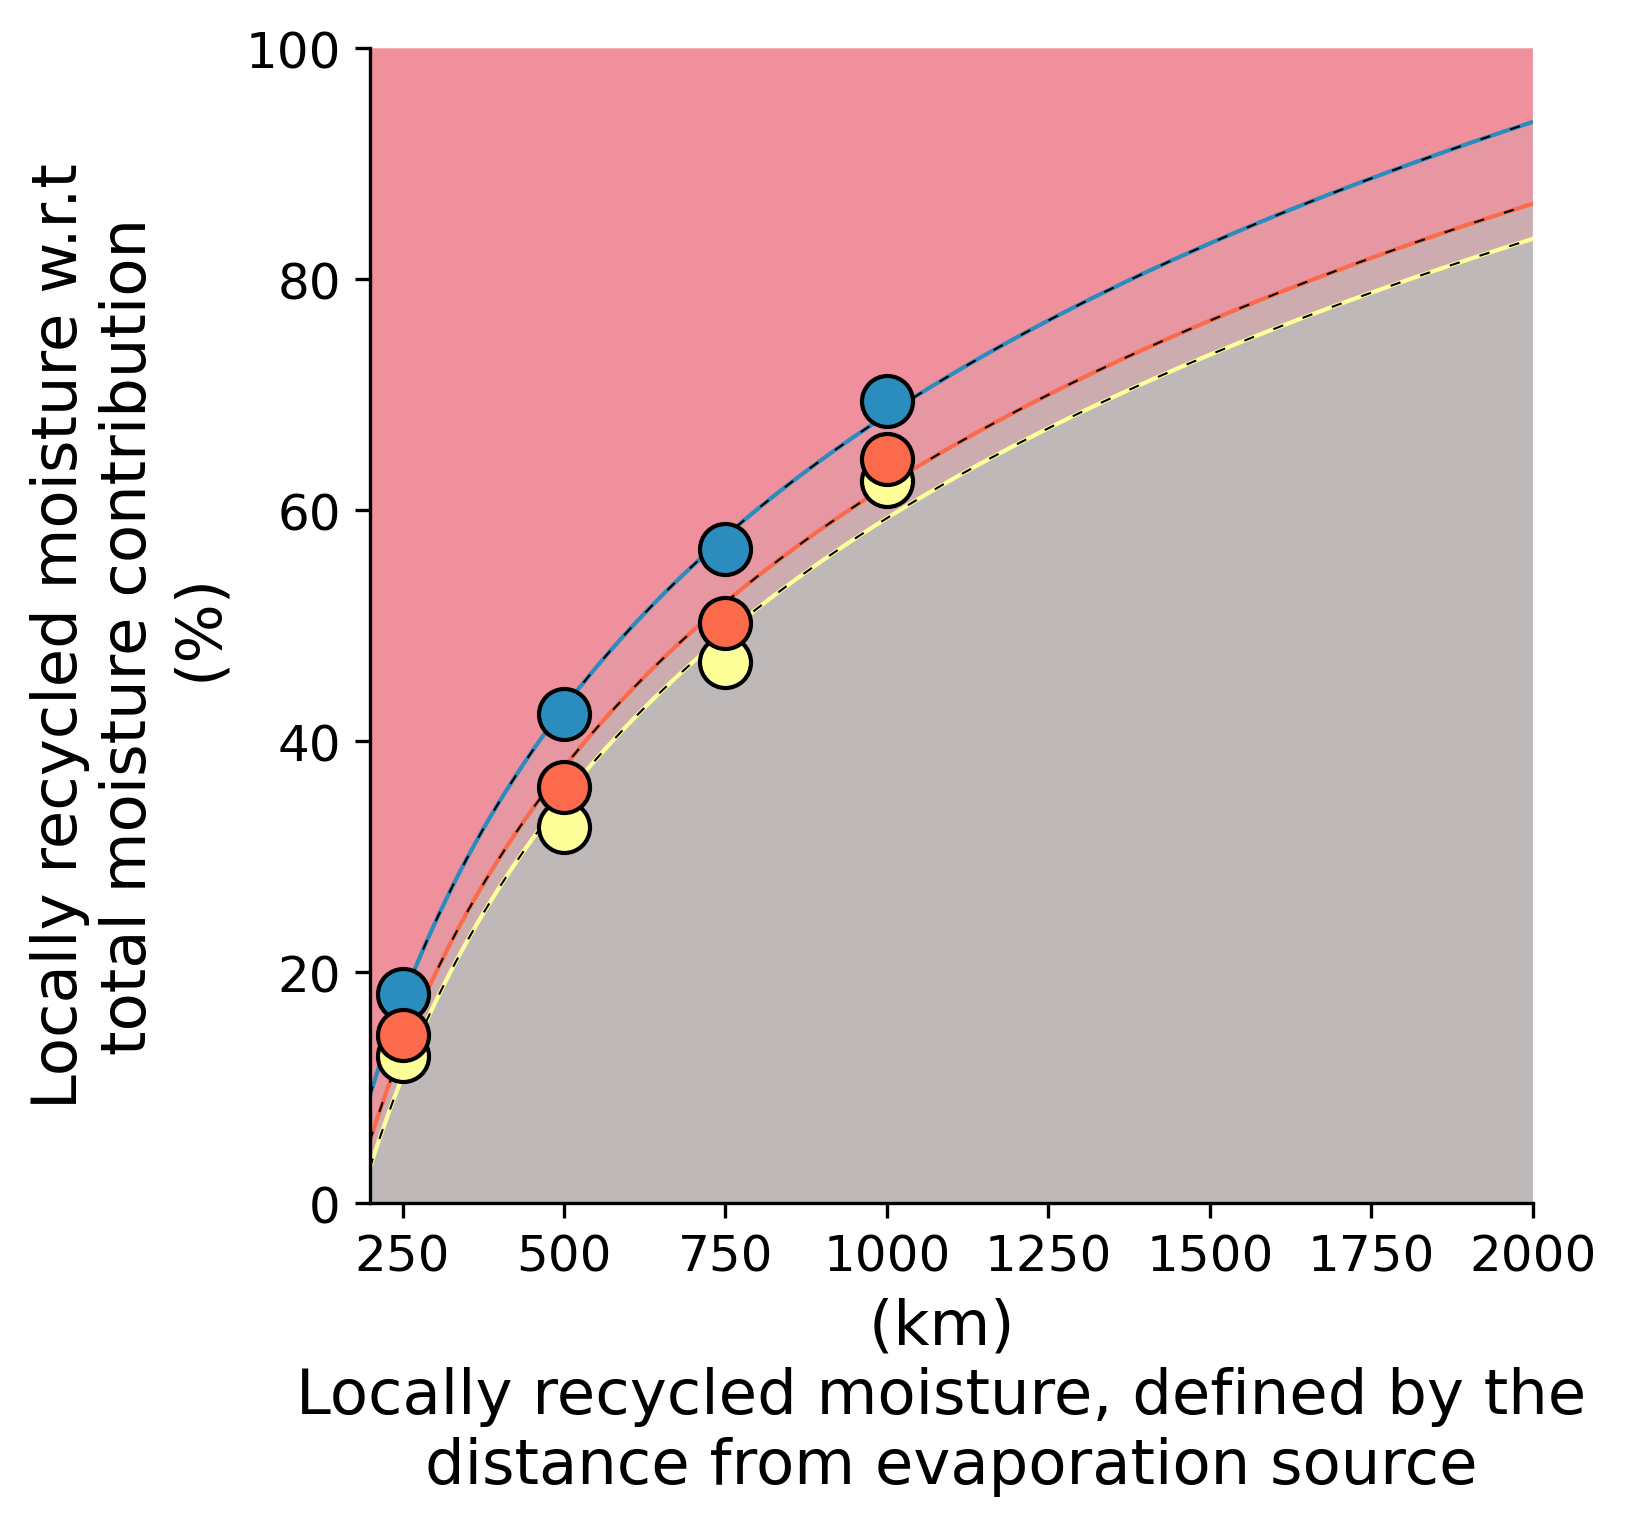

In [392]:
fig, ax = plt.subplots(1,1, figsize=(5,5), dpi = 300)
color_f = ['#ada6a6','#ed7281'] #['#5ab4ac', '#ed7281']
for stakeholders, color in zip(['Smallholders','Mediumholders', 'Largeholders'], ['#2B8CBE','#FFFF99','#FB6A4A']):
    loc_recycling_dist = []
    for grid in [9,19,27,37]:
        sr, total = stakeholder_LU_footprint_dataframe_local(stakeholders, grid, simulation = 'Forest_only')['Footprint'].sum(), stakeholder_LU_footprint_dataframe(stakeholders, simulation = 'Forest_only')['Footprint'].sum()
        sr = sr/total*100
        loc_recycling_dist.append(sr)
    recycling_influence_log([250,500,750,1000], loc_recycling_dist, color = color, ax = ax)
    ax.fill_between(np.linspace(0,MAX_X,np.array(fit_y).shape[0]), np.array(fit_y), step="pre", 
                    alpha=0.4, color = color_f[0], edgecolor = None, zorder = -10)
    ax.fill_between(np.linspace(0,MAX_X,np.array(fit_y).shape[0]), np.array(fit_y), 100, 
                    step="pre", alpha=0.4, color = color_f[1], edgecolor = None, zorder = -10)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.tick_params(axis='x',          # changes apply to the x-axis
                which='both',      # both major and minor ticks are affected
                bottom=True,      # ticks along the bottom edge are off
                top=False,         # ticks along the top edge are off
                labelbottom=True)
ax.set_ylim(0,100)
#ax.set_xlim(200,1100)
ax.set_xticks(np.arange(250, 2001, 250))
ax.set_xlabel('(km) \nLocally recycled moisture, defined by the \ndistance from evaporation source', fontsize = 15)
ax.set_ylabel('Locally recycled moisture w.r.t \ntotal moisture contribution \n(%)', fontsize = 15)
ax.set_xlim(200,MAX_X)

plt.show()

In [14]:
def Water_footprint_stakeholder_local(stakeholder,grid):
    Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+str(grid)+'x'+str(grid)+'_.nc').Evap_footprint[::-1,:].sel(lat = slice(-39.25,10.25), lon = slice(280,330))[:,:-1]
    Water_footprint = Water_footprint.where(Stakeholder.values<=3)
    Water_footprint = ((Water_footprint/10**6)*(grid_area.values/10**6))
    return Water_footprint

def Water_footprint_stakeholder_local_forest(stakeholder,grid):
    Water_footprint = xr.open_dataset('/home/chandra/data/Paper4/Output/Moisture_recycling_runs/Forwardtracking_'+stakeholder+'_'+str(grid)+'x'+str(grid)+'_forest.nc').Evap_footprint[::-1,:].sel(lat = slice(-39.25,10.25), lon = slice(280,330))[:,:-1]
    Water_footprint = Water_footprint.where(Stakeholder.values<=3)
    Water_footprint = ((Water_footprint/10**6)*(grid_area.values/10**6))
    return Water_footprint

def stakeholder_LU_footprint_dataframe_local(stakeholder, grid, simulation = 'All'):
    if simulation == 'Forest_only':
        Water_footprint = Water_footprint_stakeholder_local_forest(stakeholder, grid)
        sim_add = '<br>forest'
    else:
        Water_footprint = Water_footprint_stakeholder_local(stakeholder, grid)
        sim_add = ''
    print('All_Water_footprint_'+stakeholder,np.nansum(Water_footprint.values))
    if stakeholder == 'Smallholders':
        stakeholder_name = 'Smallholders'+sim_add
    if stakeholder == 'Mediumholders':
        stakeholder_name = 'Medium<br>landholders'+sim_add
    if stakeholder == 'Largeholders':
        stakeholder_name = 'Large<br>landholders'+sim_add
    #Water_f_total = np.nansum(Water_footprint.values)
    for i in range(1,5):
        WF_SM = Water_footprint.where(Stakeholder.values == i)
        if i == 1:
            Sink = 'Smallholders'
        if i == 2:
            Sink = 'Medium<br>landholders'
        if i == 3:
            Sink = 'Large<br>landholders'
        if i == 4:
            Sink = ' Remote'
        if i == 5:
            continue
        #print('Water_footprint_'+stakeholder+'_to_'+Sink, np.nansum(WF_SM.values))
        Total = np.nansum(WF_SM.values)
        a = []
        a.append(np.nansum((Grid('Forest').values*WF_SM).values))
        a.append(np.nansum((Grid('NonForest').values*WF_SM).values))
        a.append(np.nansum((Grid('Crop').values*WF_SM).values))
        a.append(np.nansum((Grid('Pasture').values*WF_SM).values))
        a.append(Total-np.sum(a))
        #print(a)
        if i == 1:
            df = pd.DataFrame({'Source': [stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name], 
                               'Stakeholder_sink': [Sink,Sink,Sink,Sink,Sink],
                               'Landuse': ['Forest', 'Non forest', 'Crop', 'Pasture', 'Others'],
                               'Footprint': np.array(a).flatten()})
        else:
            df_add = pd.DataFrame({'Source': [stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name,stakeholder_name], 
                               'Stakeholder_sink': [Sink,Sink,Sink,Sink,Sink],
                               'Landuse': ['Forest', 'Non forest', 'Crop', 'Pasture', 'Others'],
                               'Footprint': np.array(a).flatten()})
            df = pd.concat([df,df_add], ignore_index=True)
    df_other = pd.DataFrame({'Source': [stakeholder_name], 
                               'Stakeholder_sink': ['Other'],
                               'Landuse': ['Others'],
                               'Footprint': np.nansum(Water_footprint.values)-df['Footprint'].sum()})
    df = pd.concat([df,df_other], ignore_index=True)
    return df

All_Water_footprint_Smallholders 465.2047929994362
All_Water_footprint_Smallholders 2999.333303480364


/tmp/user/1011/ipykernel_1170369/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html

/tmp/user/1011/ipykernel_1170369/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



All_Water_footprint_Smallholders 1001.5998846004165
All_Water_footprint_Smallholders 2999.333303480364


/tmp/user/1011/ipykernel_1170369/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



All_Water_footprint_Smallholders 1296.9283948539864
All_Water_footprint_Smallholders 2999.333303480364


/tmp/user/1011/ipykernel_1170369/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



... (15 outputs left out)

/tmp/user/1011/ipykernel_1170369/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



All_Water_footprint_Largeholders 2776.2649491488573
All_Water_footprint_Largeholders 4683.325098074001


/tmp/user/1011/ipykernel_1170369/1464958096.py:20: DeprecationWarning:

open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html



solution:
31.597208 log(x) + -160.373523 = y
errors:
[[ 0.67515869]
 [-0.84488686]
 [-1.21779482]
 [ 1.38752299]]
residual:
2.1396068173805327


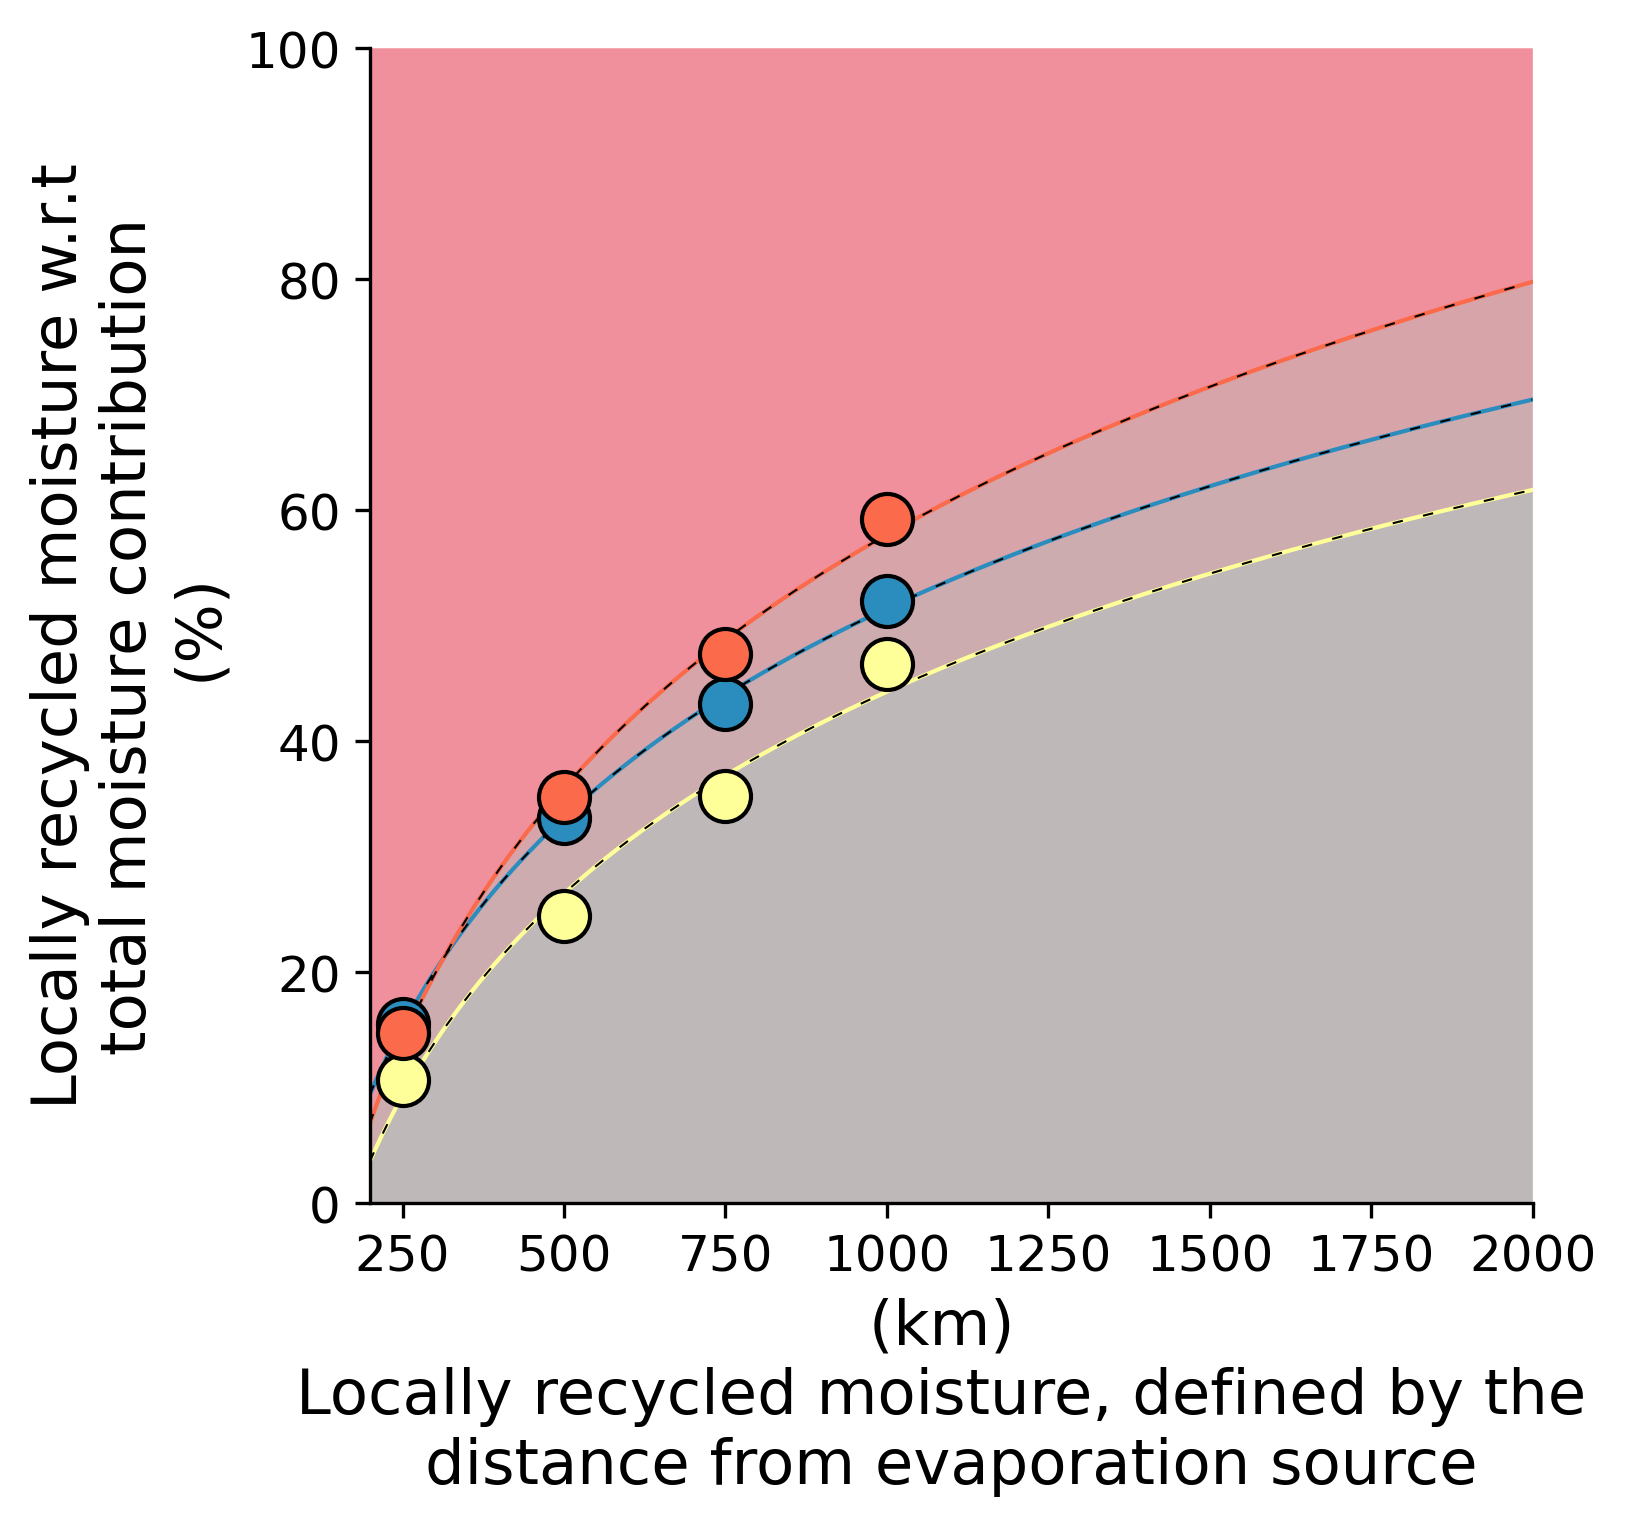

In [56]:
##### For all landuse

fig, ax = plt.subplots(1,1, figsize=(5,5), dpi = 300)
color_f = ['#ada6a6','#ed7281'] #['#5ab4ac', '#ed7281']
for stakeholders, color in zip(['Smallholders','Mediumholders', 'Largeholders'], ['#2B8CBE','#FFFF99','#FB6A4A']):
    loc_recycling_dist = []
    for grid in [9,19,27,37]:
        sr, total = stakeholder_LU_footprint_dataframe_local(stakeholders, grid, simulation = 'All')['Footprint'].sum(), stakeholder_LU_footprint_dataframe(stakeholders)['Footprint'].sum()
        sr = sr/total*100
        loc_recycling_dist.append(sr)
    recycling_influence_log([250,500,750,1000], loc_recycling_dist, color = color, ax = ax)
    ax.fill_between(np.linspace(0,MAX_X,np.array(fit_y).shape[0]), np.array(fit_y), step="pre", 
                    alpha=0.4, color = color_f[0], edgecolor = None, zorder = -10)
    ax.fill_between(np.linspace(0,MAX_X,np.array(fit_y).shape[0]), np.array(fit_y), 100, 
                    step="pre", alpha=0.4, color = color_f[1], edgecolor = None, zorder = -10)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.tick_params(axis='x',          # changes apply to the x-axis
                which='both',      # both major and minor ticks are affected
                bottom=True,      # ticks along the bottom edge are off
                top=False,         # ticks along the top edge are off
                labelbottom=True)
ax.set_ylim(0,100)
#ax.set_xlim(200,1100)
ax.set_xticks(np.arange(250, 2001, 250))
ax.set_xlabel('(km) \nLocally recycled moisture, defined by the \ndistance from evaporation source', fontsize = 15)
ax.set_ylabel('Locally recycled moisture w.r.t \ntotal moisture contribution \n(%)', fontsize = 15)
ax.set_xlim(200,MAX_X)

plt.show()

In [7]:
print(np.median(np.array([465,1001,1296,1563])/2999))
print(np.median(np.array([64,149,212,281])/602))
print(np.median(np.array([691,1645,2228,2776])/4683))

0.3829609869956652
0.29983388704318936
0.4135169762972454


All_Water_footprint_Smallholders 465.2047929994362
312.59325215859957
All_Water_footprint_Smallholders 2999.333303480364


/tmp/user/1011/ipykernel_3815894/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]
/tmp/user/1011/ipykernel_3815894/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


All_Water_footprint_Smallholders 1001.5998846004165
604.2208729663439
All_Water_footprint_Smallholders 2999.333303480364


/tmp/user/1011/ipykernel_3815894/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


All_Water_footprint_Smallholders 1296.9283948539864
733.8156610942077
All_Water_footprint_Smallholders 2999.333303480364


/tmp/user/1011/ipykernel_3815894/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


... (14 outputs left out)

1633.912123094126
All_Water_footprint_Largeholders 4683.325098074001
All_Water_footprint_Largeholders 2776.2649491488573


/tmp/user/1011/ipykernel_3815894/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


2012.2225760735291
All_Water_footprint_Largeholders 4683.325098074001
solution:
22.323978 log(x) + -112.100027 = y
errors:
[[ 0.39005107]
 [-0.44870372]
 [-0.79847826]
 [ 0.85713091]]
residual:
1.3136650268061247


/tmp/user/1011/ipykernel_3815894/1464958096.py:20: DeprecationWarning: open_rasterio is Deprecated in favor of rioxarray. For information about transitioning, see: https://corteva.github.io/rioxarray/stable/getting_started/getting_started.html
  Grid_conv = xr.open_rasterio('/home/chandra/data/Paper4/Data_previous_literature/Grid_025/Grid_'+Class+'.tif')[0]


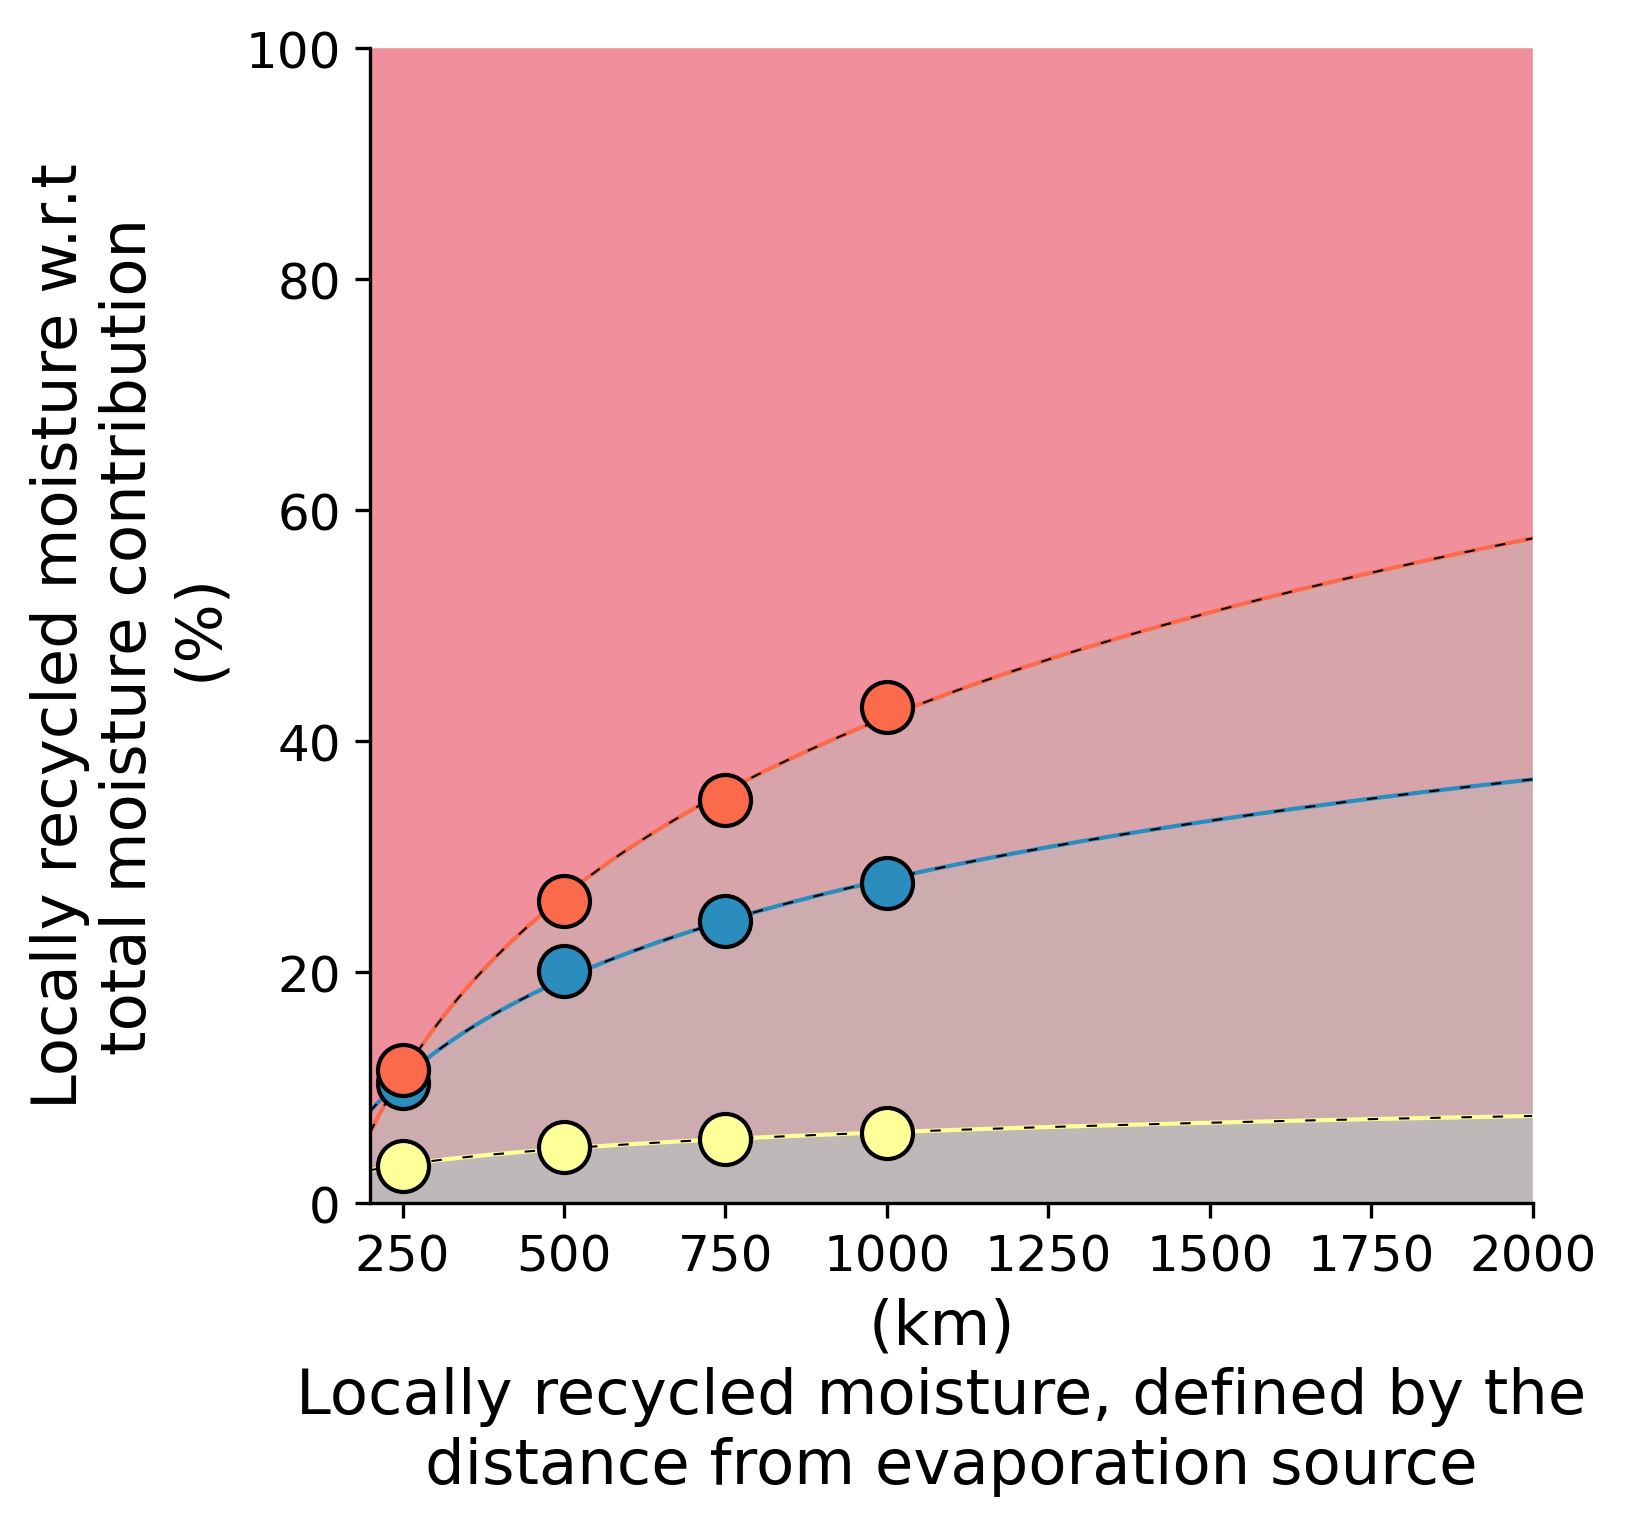

In [23]:
##### For all landuse

fig, ax = plt.subplots(1,1, figsize=(5,5), dpi = 300)
color_f = ['#ada6a6','#ed7281'] #['#5ab4ac', '#ed7281']
for stakeholders, color in zip(['Smallholders','Mediumholders', 'Largeholders'], ['#2B8CBE','#FFFF99','#FB6A4A']):
#for stakeholders, color in zip(['Smallholders'], ['#2B8CBE']):
    loc_recycling_dist = []
    for grid in [9,19,27,37]:
        if stakeholders == 'Smallholders':
            stakeholder_name = 'Smallholders'
        if stakeholders == 'Mediumholders':
            stakeholder_name = 'Medium<br>landholders'
        if stakeholders == 'Largeholders':
            stakeholder_name = 'Large<br>landholders'
            
        df_1 = stakeholder_LU_footprint_dataframe_local(stakeholders, grid, simulation = 'All')
        sr = df_1.where((df_1['Source'] == stakeholder_name) & (df_1['Stakeholder_sink'] == stakeholder_name)).dropna()['Footprint'].sum()
        print(sr)
        total = stakeholder_LU_footprint_dataframe(stakeholders)['Footprint'].sum()
        
        sr = sr/total*100
        loc_recycling_dist.append(sr)
    recycling_influence_log([250,500,750,1000], loc_recycling_dist, color = color, ax = ax)
    ax.fill_between(np.linspace(0,MAX_X,np.array(fit_y).shape[0]), np.array(fit_y), step="pre", 
                    alpha=0.4, color = color_f[0], edgecolor = None, zorder = -10)
    ax.fill_between(np.linspace(0,MAX_X,np.array(fit_y).shape[0]), np.array(fit_y), 100, 
                    step="pre", alpha=0.4, color = color_f[1], edgecolor = None, zorder = -10)

ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.tick_params(axis='x',          # changes apply to the x-axis
                which='both',      # both major and minor ticks are affected
                bottom=True,      # ticks along the bottom edge are off
                top=False,         # ticks along the top edge are off
                labelbottom=True)
ax.set_ylim(0,100)
#ax.set_xlim(200,1100)
ax.set_xticks(np.arange(250, 2001, 250))
ax.set_xlabel('(km) \nLocally recycled moisture, defined by the \ndistance from evaporation source', fontsize = 15)
ax.set_ylabel('Locally recycled moisture w.r.t \ntotal moisture contribution \n(%)', fontsize = 15)
ax.set_xlim(200,MAX_X)

plt.show()

In [24]:
print(np.median(np.array([312.59325215859957,604.2208729663439,733.8156610942077,831])/2999))
print(np.median(np.array([20,30,34,37])/602))
print(np.median(np.array([541,1226,1634,2012])/4683))

0.22308044915981187
0.053156146179401995
0.3053598120862695
